**TRAINING RL MODEL**


🌾 COMPLETE CROP OPTIMIZATION RL SYSTEM

🎯 NO TRAINED MODEL FOUND - STARTING TRAINING
 Loaded 197 records with columns: 1852
 Dataset augmented: 197 → 985 records
 FIXED Surrogate model trained:
   Train R²: 0.950 | Test R²: 0.943
 Environment Configuration:
   • State Dimension:  55
   • Action Dimension: 10
   • Crops: Cotton, Wheat, Rice, Potato, Tomato, Sugarcane
 PPO Trainer initialized on cpu
   Hidden Dim: 128, LR Actor: 3.0e-05, LR Critic: 8.0e-05

 Starting PPO Training with Accuracy Tracking...
Iter | Reward (PKR) | Accuracy (%) | P-Loss | V-Loss
------------------------------------------------------------
   1 |      50,207 | 🟢   84.5% |  0.321 | 30.196
    🎯 NEW BEST! Reward: 50,207 PKR, Accuracy: 84.5%
   2 |     105,402 | 🟢   78.9% |  0.332 | 25.933
    🎯 NEW BEST! Reward: 105,402 PKR, Accuracy: 78.9%
   3 |     127,108 | 🟢   71.5% |  0.344 | 25.385
    🎯 NEW BEST! Reward: 127,108 PKR, Accuracy: 71.5%
   4 |     150,868 | 🟢   94.0% |  0.335 | 27.237
    🎯 NEW BEST! Reward

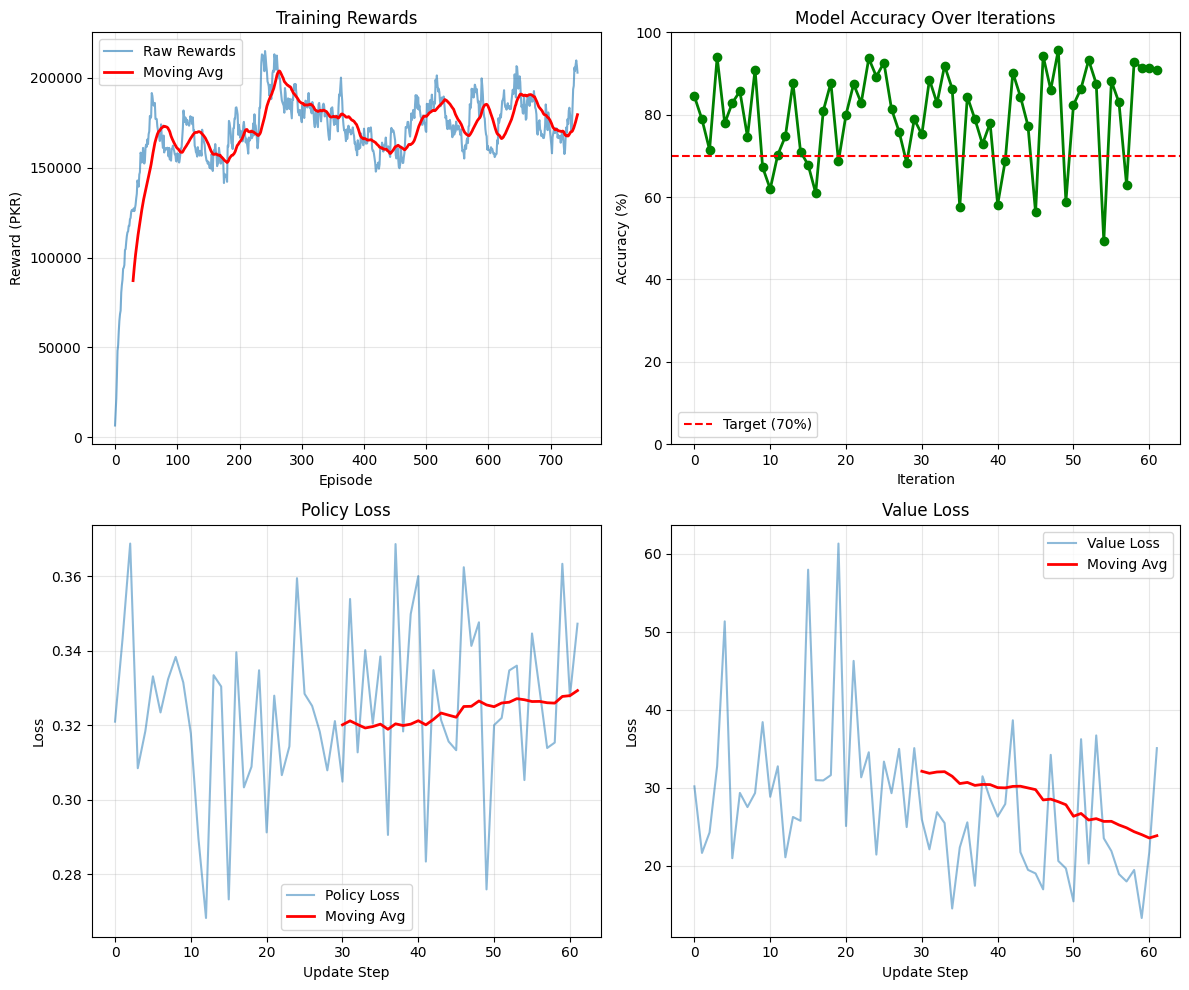

 Training plots saved as 'training_results_with_accuracy.png'

 TRAINING COMPLETE!
 Best Reward: 205,183 PKR
 Best Accuracy: 95.7%
 Final Accuracy: 90.8%

 Training completed successfully!
 Model saved as 'crop_ppo_model.pt'
 Training plots saved as 'training_results_with_accuracy.png'


In [ ]:
"""
COMPLETE CROP OPTIMIZATION RL SYSTEM WITH ACTION INTERPRETER
Training + Human-Readable Recommendations - FOR PyTorch 2.6
"""

import os
import numpy as np
import pandas as pd
import gymnasium as gym
from gymnasium import spaces
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal
import matplotlib.pyplot as plt
import warnings
from typing import Optional
import math
import json

warnings.filterwarnings('ignore')

# ---------------------- Neural Network Definitions ----------------------
class PPOActor(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim=128):
        super(PPOActor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
        )
        self.mu = nn.Linear(hidden_dim//2, action_dim)
        self.sigma = nn.Linear(hidden_dim//2, action_dim)

        nn.init.orthogonal_(self.mu.weight, gain=0.01)
        nn.init.constant_(self.mu.bias, 0.0)
        nn.init.orthogonal_(self.sigma.weight, gain=0.01)
        nn.init.constant_(self.sigma.bias, 0.0)

    def forward(self, x):
        features = self.net(x)
        mu = torch.tanh(self.mu(features))
        sigma = torch.nn.functional.softplus(self.sigma(features)) + 1e-4
        return mu, sigma

    def get_action(self, state):
        mu, sigma = self.forward(state)
        dist = Normal(mu, sigma)
        action = dist.rsample()
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action, log_prob

    def evaluate(self, states, actions):
        mu, sigma = self.forward(states)
        dist = Normal(mu, sigma)
        log_probs = dist.log_prob(actions).sum(dim=-1)
        entropy = dist.entropy().sum(dim=-1)
        return log_probs, entropy

class PPOCritic(nn.Module):
    def __init__(self, state_dim, hidden_dim=128):
        super(PPOCritic, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
            nn.Linear(hidden_dim//2, 1)
        )
        nn.init.orthogonal_(self.net[0].weight, gain=1.0)
        nn.init.constant_(self.net[0].bias, 0.0)
        nn.init.orthogonal_(self.net[2].weight, gain=1.0)
        nn.init.constant_(self.net[2].bias, 0.0)
        nn.init.orthogonal_(self.net[4].weight, gain=1.0)
        nn.init.constant_(self.net[4].bias, 0.0)

    def forward(self, x):
        return self.net(x)

# ---------------------- Advanced Crop RL Environment ----------------------
class AdvancedCropOptimizationEnv(gym.Env):
    """Multi-Factor Model-Based RL Environment for Comprehensive Crop Optimization"""

    metadata = {'render_modes': ['human']}

    CROP_DISTRICTS = {
        'Cotton': ['Bahawalpur', 'D.G. Khan', 'Ghotki', 'Hyderabad', 'Khairpur', 'Khanewal', 'Mirpurkhas', 'Multan', 'Rahimyar Khan', 'Sukkur', 'Thatta'],
        'Wheat': ['Charsadda', 'Chiniot', 'Dir Upper', 'Gujranwala', 'Gujrat', 'Hafizabad', 'Jhang', 'Lahore', 'Mirpurkhas', 'Nankana Sahib', 'Narowal', 'Peshawar', 'Rahimyar Khan', 'Sargodha', 'Shangla', 'Sheikhupura', 'Sialkot', 'Turbat', 'Wazirabad'],
        'Rice': ['Rahimyar Khan', 'Sargodha', 'Turbat','kasur','Larkana','Gujranwala','Sheikhupura','Hafizabad','Sialkot'],
        'Potato': ['Bahawalpur', 'Chitral', 'Khanewal', 'Mardan', 'Multan', 'Pishin', 'Quetta', 'Rahimyar Khan'],
        'Tomato': ['Bahawalpur', 'Chitral', 'D.G. Khan', 'Hyderabad', 'Khanewal', 'Mardan', 'Mirpurkhas', 'Multan', 'Pishin', 'Quetta', 'Rahimyar Khan', 'Thatta'],
        'Sugarcane': ['D.G. Khan', 'Ghotki', 'Hyderabad', 'Khairpur', 'Khanewal', 'Mirpurkhas', 'Multan', 'Sargodha', 'Sukkur', 'Thatta']
    }

    PHASES = ['Sowing', 'Vegetative', 'Harvesting']
    PHASE_MAP = {'Sowing':0,'Vegetative':1,'Harvesting':2}
    SEASONS = ['Rabi', 'Kharif']

    PRICES_PKR = {
        'fertilizer_base': 15.0, 'irrigation_base': 8.0, 'pesticide_base': 25.0,
        'seed_base': 200.0, 'soil_amendment': 10.0, 'herbicide': 30.0,
        'micronutrient': 50.0, 'labor_daily': 1500.0, 'machinery_hour': 2000.0
    }

    def __init__(self, csv_path:Optional[str]=None, n_pca_components:int=50, max_steps:int=10):
        super().__init__()
        self.n_pca_components = n_pca_components
        self.max_steps = max_steps
        self.current_step = 0

        self.df = pd.read_csv(csv_path)
        print(f" Loaded {len(self.df)} records with columns: {len(self.df.columns)}")
        self._initialize_encoders()
        self._identify_features()
        self.n_pca_components = min(self.n_pca_components, len(self.feature_cols))
        self._apply_pca()
        self._augment_dataset()
        self._train_surrogate_model()
        self._define_spaces()

        self.state = None
        self.current_district = None
        self.current_crop = None
        self.current_phase = 0
        self.current_area = 1.0
        self.current_season = 'Kharif'
        self.weather_risk = 0.5
        self.market_volatility = 0.5

    def _initialize_encoders(self):
        self.district_encoder = LabelEncoder()
        self.crop_encoder = LabelEncoder()
        self.df['district_encoded'] = self.district_encoder.fit_transform(self.df['district_name'])
        self.df['crop_encoded'] = self.crop_encoder.fit_transform(self.df['crop_name'])
        self.df['phase_encoded'] = self.df['crop_phase'].map(self.PHASE_MAP).fillna(0).astype(int)

    def _identify_features(self):
        exclude = ['district_name','crop_name','crop_phase','district_encoded','crop_encoded','phase_encoded']
        self.feature_cols = [c for c in self.df.columns if c not in exclude]
        self.df[self.feature_cols] = self.df[self.feature_cols].fillna(self.df[self.feature_cols].median())

    def _apply_pca(self):
        self.scaler = StandardScaler()
        scaled_features = self.scaler.fit_transform(self.df[self.feature_cols])
        self.pca = PCA(n_components=self.n_pca_components)
        pca_features = self.pca.fit_transform(scaled_features)
        self.pca_feature_cols = [f'pca_{i}' for i in range(self.n_pca_components)]
        self.df[self.pca_feature_cols] = pca_features

    def _augment_dataset(self):
        """Augment dataset with synthetic variations"""
        original_size = len(self.df)
        augmented_rows = []

        for noise_level in [0.03, 0.05, 0.08, 0.12]:
            for idx in range(original_size):
                row = self.df.iloc[idx].copy()
                for col in self.pca_feature_cols:
                    noise = np.random.normal(0, noise_level * abs(row[col]))
                    row[col] += noise
                augmented_rows.append(row)

        if augmented_rows:
            augmented_df = pd.DataFrame(augmented_rows)
            self.df = pd.concat([self.df, augmented_df], ignore_index=True)
            print(f" Dataset augmented: {original_size} → {len(self.df)} records")

    def _train_surrogate_model(self):
        n_samples = len(self.df)
        np.random.seed(42)

        actions = np.column_stack([
            np.random.uniform(2, 80, n_samples),
            np.random.uniform(2, 100, n_samples),
            np.random.uniform(0.5, 40, n_samples),
            np.random.uniform(4.5, 9.5, n_samples),
            np.random.uniform(5, 80, n_samples),
            np.random.uniform(1, 60, n_samples),
            np.random.uniform(0.1, 10, n_samples),
            np.random.uniform(0.2, 20, n_samples),
            np.random.uniform(8, 80, n_samples),
            np.random.uniform(0.1, 10, n_samples)
        ])

        state_features = self.df[['district_encoded','crop_encoded','phase_encoded']+self.pca_feature_cols].values
        X = np.column_stack([state_features, actions])

        base_yield = self.df['pca_0'].values
        fertilizer_effect = 3.0 * (1 - np.exp(-actions[:,0] / 15))
        irrigation_effect = 2.5 * (1 - np.exp(-actions[:,1] / 20))
        pesticide_effect = 1.5 * np.tanh(actions[:,2] / 5)

        ph_optimal = 6.5
        ph_effect = 1.2 * np.exp(-0.8 * ((actions[:,3] - ph_optimal) ** 2))

        spacing_optimal = 30
        spacing_effect = 0.8 * np.exp(-0.05 * ((actions[:,8] - spacing_optimal) ** 2))

        fertilizer_irrigation_interaction = 0.5 * np.tanh((fertilizer_effect * irrigation_effect) / 6.0)
        fertilizer_pesticide_interaction = 0.3 * (fertilizer_effect * pesticide_effect) / 4.0

        seed_density_effect = 0.6 * (1 - np.exp(-actions[:,4] / 25))
        micronutrient_effect = 0.7 * (1 - np.exp(-actions[:,7] / 6))

        noise = np.random.normal(0, 0.25, n_samples)

        y = (base_yield +
             fertilizer_effect +
             irrigation_effect +
             pesticide_effect +
             ph_effect +
             spacing_effect +
             fertilizer_irrigation_interaction +
             fertilizer_pesticide_interaction +
             seed_density_effect +
             0.4 * np.tanh(actions[:,5] / 15) +
             0.3 * np.tanh(actions[:,6] / 2) +
             micronutrient_effect +
             0.4 * np.tanh(actions[:,9] / 3) +
             noise)

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

        self.surrogate_model = RandomForestRegressor(
            n_estimators=15,
            max_depth=6,
            min_samples_split=30,
            min_samples_leaf=15,
            max_features=0.5,
            bootstrap=True,
            max_samples=0.6,
            n_jobs=-1,
            random_state=42
        )

        self.surrogate_model.fit(X_train, y_train)

        train_score = self.surrogate_model.score(X_train, y_train)
        test_score = self.surrogate_model.score(X_test, y_test)

        print(f" FIXED Surrogate model trained:")
        print(f"   Train R²: {train_score:.3f} | Test R²: {test_score:.3f}")

    def _define_spaces(self):
        self.action_space = spaces.Box(
            low=np.array([0, 0, 0, 5.5, 10, 0, 0, 0, 15, 0]),
            high=np.array([50, 50, 20, 8.0, 40, 30, 5, 10, 45, 5]),
            dtype=np.float32
        )
        obs_dim = 3 + self.n_pca_components + 2
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(obs_dim,), dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if options and 'district' in options and 'crop' in options:
            self.current_district = options['district']
            self.current_crop = options['crop']
            self.current_area = options.get('area',1.0)
            self.current_season = options.get('season', 'Kharif')
            self.weather_risk = options.get('weather_risk', np.random.uniform(0.2, 0.8))
            self.market_volatility = options.get('market_volatility', np.random.uniform(0.3, 0.7))
        else:
            self.current_crop = np.random.choice(list(self.CROP_DISTRICTS.keys()))
            self.current_district = np.random.choice(self.CROP_DISTRICTS[self.current_crop])
            self.current_area = np.random.uniform(0.5,10.0)
            self.current_season = np.random.choice(self.SEASONS)
            self.weather_risk = np.random.uniform(0.2, 0.8)
            self.market_volatility = np.random.uniform(0.3, 0.7)

        self.current_phase = 0
        self.current_step = 0
        self.state = self._get_state_vector()
        return self.state, {'district': self.current_district, 'crop': self.current_crop}

    def _get_state_vector(self):
        mask = (self.df['district_name']==self.current_district)&(self.df['crop_name']==self.current_crop)&(self.df['phase_encoded']==self.current_phase)
        row = self.df[mask].iloc[0] if mask.sum()>0 else self.df.sample(1).iloc[0]
        season_encoded = 1.0 if self.current_season == 'Kharif' else 0.0
        state = np.concatenate([
            [row['district_encoded']], [row['crop_encoded']], [self.current_phase],
            row[self.pca_feature_cols].values, [season_encoded], [self.weather_risk]
        ])
        return state.astype(np.float32)

    def step(self, action):
        self.current_step += 1
        action = np.clip(action, self.action_space.low, self.action_space.high)
        state_action = np.concatenate([self.state[:-2], action])
        yield_proxy = self.surrogate_model.predict([state_action])[0]

        reward = self._calculate_multiobjective_reward(action, yield_proxy)

        self.current_phase = min(self.current_phase+1,2)
        self.state = self._get_state_vector()
        done = (self.current_phase==2) or (self.current_step>=self.max_steps)

        info = {
            'district': self.current_district, 'crop': self.current_crop,
            'phase': self.PHASES[self.current_phase-1] if self.current_phase > 0 else 'Sowing',
        }
        return self.state, reward, done, False, info

    def _calculate_multiobjective_reward(self, action, yield_proxy):
        min_y, max_y = self.df['pca_0'].min(), self.df['pca_0'].max()
        norm_yield = (yield_proxy - min_y) / (max_y - min_y + 1e-6)
        phase_mult = [1.2, 1.0, 0.8][self.current_phase]
        weather_factor = 1.0 - (0.3 * self.weather_risk)
        season_factor = 1.1 if self.current_season == 'Kharif' else 0.95

        yield_benefit = norm_yield * 50000 * self.current_area * phase_mult * weather_factor * season_factor

        fertilizer_cost = action[0] * self.PRICES_PKR['fertilizer_base'] * self.current_area
        irrigation_cost = action[1] * self.PRICES_PKR['irrigation_base'] * self.current_area
        pesticide_cost = action[2] * self.PRICES_PKR['pesticide_base'] * self.current_area
        seed_cost = action[4] * self.PRICES_PKR['seed_base'] * self.current_area
        soil_amendment_cost = action[5] * self.PRICES_PKR['soil_amendment'] * self.current_area * 1000
        herbicide_cost = action[6] * self.PRICES_PKR['herbicide'] * self.current_area
        micronutrient_cost = action[7] * self.PRICES_PKR['micronutrient'] * self.current_area
        labor_cost = self.PRICES_PKR['labor_daily'] * 5 * self.current_area
        machinery_cost = self.PRICES_PKR['machinery_hour'] * 3 * self.current_area

        total_cost = (fertilizer_cost + irrigation_cost + pesticide_cost + seed_cost +
                     soil_amendment_cost + herbicide_cost + micronutrient_cost +
                     labor_cost + machinery_cost)

        sustainability_score = (100 - (action[0]/50)*20 - (action[2]/20)*15 -
                               (action[6]/5)*10 + (action[5]/30)*15 + (action[9]/5)*10)
        sustainability_bonus = sustainability_score * 500

        optimal_ph = 6.5
        ph_penalty = abs(action[3] - optimal_ph) * 1000
        soil_health_bonus = max(0, 5000 - ph_penalty)

        market_risk_penalty = self.market_volatility * total_cost * 0.1
        economic_reward = yield_benefit - total_cost - market_risk_penalty
        total_reward = economic_reward + sustainability_bonus + soil_health_bonus

        if self.current_phase == 2:
            total_reward += 5000.0

        return total_reward

# ---------------------- Improved PPO Trainer with Accuracy ----------------------
class ImprovedPPOTrainer:
    def __init__(self, env, state_dim:int, action_dim:int,
                 hidden_dim:int=128,
                 lr_actor:float=3e-5,
                 lr_critic:float=8e-5,
                 gamma:float=0.99, gae_lambda:float=0.97,
                 clip_epsilon:float=0.15,
                 entropy_coef:float=0.03,
                 value_coef:float=0.25, max_grad_norm:float=0.6,
                 kl_penalty_coef:float=0.1,
                 reward_scale:float=2e4,
                 advantage_normalization:bool=True,
                 device:str=None):

        if device is None:
            device = 'cuda' if torch.cuda.is_available() else 'cpu'

        self.env = env
        self.device = device
        self.gamma = gamma
        self.gae_lambda = gae_lambda
        self.clip_epsilon = clip_epsilon
        self.entropy_coef = entropy_coef
        self.value_coef = value_coef
        self.max_grad_norm = max_grad_norm
        self.kl_penalty_coef = kl_penalty_coef
        self.reward_scale = reward_scale
        self.advantage_normalization = advantage_normalization

        self.actor = PPOActor(state_dim, action_dim, hidden_dim).to(self.device)
        self.critic = PPOCritic(state_dim, hidden_dim).to(self.device)

        self.initial_lr_actor = lr_actor
        self.initial_lr_critic = lr_critic
        self.actor_optimizer = optim.Adam(self.actor.parameters(), lr=lr_actor, eps=1e-8)
        self.critic_optimizer = optim.Adam(self.critic.parameters(), lr=lr_critic, eps=1e-8)

        self.smoothed_reward = 0.0
        self.reward_smoothing = 0.95
        self.best_reward = -np.inf
        self.best_accuracy = 0.0
        self.patience = 40
        self.patience_counter = 0

        self.episode_rewards, self.episode_lengths = [], []
        self.policy_losses, self.value_losses = [], []
        self.kl_divergences = []
        self.accuracies = []

        self.obs_count = 0
        self.obs_mean = np.zeros(state_dim, dtype=np.float32)
        self.obs_var = np.ones(state_dim, dtype=np.float32)

        print(f" PPO Trainer initialized on {self.device}")
        print(f"   Hidden Dim: {hidden_dim}, LR Actor: {lr_actor:.1e}, LR Critic: {lr_critic:.1e}")

    def _update_obs_rms(self, obs_batch:np.ndarray):
        for obs in obs_batch:
            self.obs_count += 1
            delta = obs - self.obs_mean
            self.obs_mean += delta / self.obs_count
            delta2 = obs - self.obs_mean
            self.obs_var += (delta * delta2)

    def _get_obs_stats(self):
        if self.obs_count < 2:
            return self.obs_mean, np.sqrt(self.obs_var + 1e-8)
        var = self.obs_var / (self.obs_count - 1)
        return self.obs_mean, np.sqrt(var + 1e-8)

    def compute_gae(self, rewards:list, values:list, dones:list, next_value:float):
        advantages, returns = [], []
        gae = 0.0
        for step in reversed(range(len(rewards))):
            next_non_terminal = 1.0 - float(dones[step])
            next_values = next_value if step == len(rewards)-1 else values[step+1]
            delta = rewards[step] + self.gamma * next_values * next_non_terminal - values[step]
            gae = delta + self.gamma * self.gae_lambda * next_non_terminal * gae
            advantages.insert(0, gae)
            returns.insert(0, gae + values[step])
        return (torch.tensor(advantages, dtype=torch.float32, device=self.device),
                torch.tensor(returns, dtype=torch.float32, device=self.device))

    def collect_trajectories(self, n_episodes:int=12):
        states, actions, rewards, log_probs, values, dones = [], [], [], [], [], []
        all_states_for_rms = []

        for _ in range(n_episodes):
            state, _ = self.env.reset()
            done = False
            local_rewards = []

            while not done:
                all_states_for_rms.append(np.array(state, dtype=np.float32))

                state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
                with torch.no_grad():
                    action, log_prob = self.actor.get_action(state_tensor)
                    value = self.critic(state_tensor)

                action_np = np.clip(action.cpu().numpy()[0], self.env.action_space.low, self.env.action_space.high)
                next_state, reward, done, truncated, info = self.env.step(action_np)

                scaled_reward = float(reward) / float(self.reward_scale)

                states.append(state)
                actions.append(action_np)
                rewards.append(scaled_reward)
                log_probs.append(log_prob.item())
                values.append(float(value.item()))
                dones.append(done or truncated)

                local_rewards.append(reward)
                state = next_state

            episode_reward = np.sum(local_rewards)
            self.smoothed_reward = (self.reward_smoothing * self.smoothed_reward +
                                    (1 - self.reward_smoothing) * episode_reward)
            self.episode_rewards.append(self.smoothed_reward)
            self.episode_lengths.append(len(local_rewards))

        if len(all_states_for_rms) > 0:
            self._update_obs_rms(np.array(all_states_for_rms))

        next_state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
        with torch.no_grad():
            next_value = float(self.critic(next_state_tensor).item())

        advantages, returns = self.compute_gae(rewards, values, dones, next_value)

        states_t = torch.FloatTensor(np.array(states)).to(self.device)
        actions_t = torch.FloatTensor(np.array(actions)).to(self.device)
        old_log_probs_t = torch.FloatTensor(np.array(log_probs)).to(self.device)
        values_t = torch.FloatTensor(np.array(values)).to(self.device)

        return states_t, actions_t, old_log_probs_t, returns, advantages, values_t

    def _calculate_accuracy(self, n_test_episodes:int=5):
        test_rewards = []
        predicted_values = []
        actual_rewards = []

        for _ in range(n_test_episodes):
            state, _ = self.env.reset()
            done = False
            episode_reward = 0

            while not done:
                state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
                with torch.no_grad():
                    action, _ = self.actor.get_action(state_tensor)
                    predicted_value = self.critic(state_tensor).item()

                action_np = np.clip(action.cpu().numpy()[0], self.env.action_space.low, self.env.action_space.high)
                next_state, reward, done, truncated, info = self.env.step(action_np)

                predicted_values.append(predicted_value)
                actual_rewards.append(reward)
                episode_reward += reward
                state = next_state

            test_rewards.append(episode_reward)

        if len(predicted_values) > 1:
            try:
                correlation = np.corrcoef(predicted_values, actual_rewards)[0, 1]
                correlation = np.nan_to_num(correlation)
                accuracy = max(0.0, (correlation + 1) * 50)
            except:
                accuracy = 0.0
        else:
            accuracy = 0.0

        return accuracy, np.mean(test_rewards)

    def update_policy(self, states, actions, old_log_probs, returns, advantages,
                     old_values, n_epochs:int=4, batch_size:int=128):

        if self.advantage_normalization and len(advantages) > 1:
            advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        n_samples = states.shape[0]
        if n_samples == 0:
            return

        indices = np.arange(n_samples)

        for epoch in range(n_epochs):
            np.random.shuffle(indices)
            for start in range(0, n_samples, batch_size):
                end = start + batch_size
                batch_idx = indices[start:end]
                if len(batch_idx) == 0:
                    continue

                batch_states = states[batch_idx]
                batch_actions = actions[batch_idx]
                batch_old_log_probs = old_log_probs[batch_idx]
                batch_returns = returns[batch_idx].unsqueeze(-1)
                batch_advantages = advantages[batch_idx].unsqueeze(-1)
                batch_old_values = old_values[batch_idx].unsqueeze(-1)

                new_log_probs, entropy = self.actor.evaluate(batch_states, batch_actions)
                new_values = self.critic(batch_states).unsqueeze(-1)

                with torch.no_grad():
                    approx_kl = (batch_old_log_probs - new_log_probs).mean().item()
                self.kl_divergences.append(abs(approx_kl))

                ratios = torch.exp(new_log_probs - batch_old_log_probs)

                surr1 = ratios * batch_advantages
                surr2 = torch.clamp(ratios, 1.0 - self.clip_epsilon, 1.0 + self.clip_epsilon) * batch_advantages
                policy_loss = -torch.min(surr1, surr2).mean()

                entropy_loss = - self.entropy_coef * entropy.mean()

                value_pred_clipped = batch_old_values + (new_values - batch_old_values).clamp(-self.clip_epsilon, self.clip_epsilon)
                value_loss_unclipped = (new_values - batch_returns).pow(2)
                value_loss_clipped = (value_pred_clipped - batch_returns).pow(2)
                value_loss = 0.5 * torch.max(value_loss_unclipped, value_loss_clipped).mean()

                self.actor_optimizer.zero_grad()
                (policy_loss + entropy_loss).backward(retain_graph=True)
                nn.utils.clip_grad_norm_(self.actor.parameters(), self.max_grad_norm)
                self.actor_optimizer.step()

                self.critic_optimizer.zero_grad()
                (self.value_coef * value_loss).backward()
                nn.utils.clip_grad_norm_(self.critic.parameters(), self.max_grad_norm)
                self.critic_optimizer.step()

                self.policy_losses.append(policy_loss.item())
                self.value_losses.append(value_loss.item())

            if len(self.kl_divergences) > 0 and self.kl_divergences[-1] > 0.3:
                break

    def _adjust_learning_rate(self, iteration, total_iterations):
        warmup_iterations = int(0.15 * total_iterations)
        if iteration < warmup_iterations and warmup_iterations > 0:
            lr_factor = (iteration + 1) / warmup_iterations
        else:
            progress = max(0.0, (iteration - warmup_iterations) / max(1, (total_iterations - warmup_iterations)))
            lr_factor = 0.5 * (1.0 + math.cos(math.pi * progress))

        new_lr_actor = self.initial_lr_actor * max(0.1, lr_factor)
        new_lr_critic = self.initial_lr_critic * max(0.1, lr_factor)

        for param_group in self.actor_optimizer.param_groups:
            param_group['lr'] = new_lr_actor
        for param_group in self.critic_optimizer.param_groups:
            param_group['lr'] = new_lr_critic

    def train(self, n_iterations:int=200, n_episodes_per_iter:int=12,
              n_epochs:int=4, batch_size:int=128, save_path:str="ppo_crop_model.pt"):

        print("\n Starting PPO Training with Accuracy Tracking...")
        print("Iter | Reward (PKR) | Accuracy (%) | P-Loss | V-Loss")
        print("-" * 60)

        for iteration in range(n_iterations):
            self._adjust_learning_rate(iteration, n_iterations)

            states, actions, log_probs, returns, advantages, values = self.collect_trajectories(n_episodes=n_episodes_per_iter)
            self.update_policy(states, actions, log_probs, returns, advantages, values,
                               n_epochs=n_epochs, batch_size=batch_size)

            accuracy, test_reward = self._calculate_accuracy(n_test_episodes=5)
            self.accuracies.append(accuracy)

            if (iteration+1) % 1 == 0:
                avg_reward = np.mean(self.episode_rewards[-n_episodes_per_iter:]) if len(self.episode_rewards) >= n_episodes_per_iter else np.mean(self.episode_rewards)
                recent_policy_loss = np.mean(self.policy_losses[-50:]) if len(self.policy_losses) > 0 else 0
                recent_value_loss = np.mean(self.value_losses[-50:]) if len(self.value_losses) > 0 else 0

                accuracy_color = ""
                if accuracy >= 70:
                    accuracy_color = "🟢"
                elif accuracy >= 50:
                    accuracy_color = "🟡"
                else:
                    accuracy_color = "🔴"

                print(f"{iteration+1:4d} | {avg_reward:>11,.0f} | {accuracy_color} {accuracy:>6.1f}% | {recent_policy_loss:>6.3f} | {recent_value_loss:>6.3f}")

                if accuracy > self.best_accuracy:
                    self.best_accuracy = accuracy

                if avg_reward > self.best_reward:
                    self.best_reward = avg_reward
                    self.patience_counter = 0
                    self.save_model(save_path.replace('.pt', '_best.pt'))
                    if accuracy >= 70:
                        print(f"     NEW BEST! Reward: {avg_reward:,.0f} PKR, Accuracy: {accuracy:.1f}%")
                else:
                    self.patience_counter += 1

                if self.patience_counter >= self.patience:
                    print(f"     Early stopping at iteration {iteration+1}")
                    break

        self.save_model(save_path)
        self.plot_training_results()

        print(f"\n" + "="*50)
        print(f" TRAINING COMPLETE!")
        print(f" Best Reward: {self.best_reward:,.0f} PKR")
        print(f" Best Accuracy: {self.best_accuracy:.1f}%")
        print(f" Final Accuracy: {self.accuracies[-1]:.1f}%")
        print("="*50)

    def save_model(self, path:str):
        torch.save({
            'actor_state_dict': self.actor.state_dict(),
            'critic_state_dict': self.critic.state_dict(),
            'actor_optimizer_state_dict': self.actor_optimizer.state_dict(),
            'critic_optimizer_state_dict': self.critic_optimizer.state_dict(),
            'best_reward': self.best_reward,
            'best_accuracy': self.best_accuracy,
            'accuracies': self.accuracies
        }, path)

    def plot_training_results(self):
        try:
            fig, axes = plt.subplots(2, 2, figsize=(12, 10))

            axes[0,0].plot(self.episode_rewards, alpha=0.6, label='Raw Rewards')
            if len(self.episode_rewards) > 10:
                axes[0,0].plot(pd.Series(self.episode_rewards).rolling(min(30, len(self.episode_rewards)//3)).mean(),
                              linewidth=2, label='Moving Avg', color='red')
            axes[0,0].set_title('Training Rewards')
            axes[0,0].set_xlabel('Episode')
            axes[0,0].set_ylabel('Reward (PKR)')
            axes[0,0].legend()
            axes[0,0].grid(True, alpha=0.3)

            if len(self.accuracies) > 0:
                axes[0,1].plot(self.accuracies, marker='o', linewidth=2, color='green')
                axes[0,1].axhline(y=70, color='red', linestyle='--', label='Target (70%)')
                axes[0,1].set_title('Model Accuracy Over Iterations')
                axes[0,1].set_xlabel('Iteration')
                axes[0,1].set_ylabel('Accuracy (%)')
                axes[0,1].set_ylim(0, 100)
                axes[0,1].legend()
                axes[0,1].grid(True, alpha=0.3)

            if len(self.policy_losses) > 0:
                axes[1,0].plot(self.policy_losses, alpha=0.5, label='Policy Loss')
                if len(self.policy_losses) > 10:
                    axes[1,0].plot(pd.Series(self.policy_losses).rolling(min(50, len(self.policy_losses)//2)).mean(),
                                  linewidth=2, label='Moving Avg', color='red')
                axes[1,0].set_title('Policy Loss')
                axes[1,0].set_xlabel('Update Step')
                axes[1,0].set_ylabel('Loss')
                axes[1,0].legend()
                axes[1,0].grid(True, alpha=0.3)

            if len(self.value_losses) > 0:
                axes[1,1].plot(self.value_losses, alpha=0.5, label='Value Loss')
                if len(self.value_losses) > 10:
                    axes[1,1].plot(pd.Series(self.value_losses).rolling(min(50, len(self.value_losses)//2)).mean(),
                                  linewidth=2, label='Moving Avg', color='red')
                axes[1,1].set_title('Value Loss')
                axes[1,1].set_xlabel('Update Step')
                axes[1,1].set_ylabel('Loss')
                axes[1,1].legend()
                axes[1,1].grid(True, alpha=0.3)

            plt.tight_layout()
            plt.savefig('training_results_with_accuracy.png', dpi=300, bbox_inches='tight')
            plt.show()

            print(" Training plots saved as 'training_results_with_accuracy.png'")

        except Exception as e:
            print("Plotting error:", e)

# ---------------------- ACTION INTERPRETER CLASS (FIXED FOR PyTorch 2.6) ----------------------
class TrainedModelInterpreter:
    def __init__(self, model_path: str = "crop_ppo_model.pt", csv_path: str = "crop_features_custom_format.csv"):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model_path = model_path
        self.csv_path = csv_path

        self.env, self.actor, self.critic = self._load_trained_model()
        self._setup_interpretation_mappings()

        print(f" Trained model loaded successfully from {model_path}")
        print(f" Device: {self.device}")

    def _load_trained_model(self):
        env = AdvancedCropOptimizationEnv(csv_path=self.csv_path, n_pca_components=50, max_steps=10)
        state_dim = env.observation_space.shape[0]
        action_dim = env.action_space.shape[0]

        print(f" State Dimension: {state_dim}, Action Dimension: {action_dim}")

        actor = PPOActor(state_dim, action_dim, hidden_dim=128).to(self.device)
        critic = PPOCritic(state_dim, hidden_dim=128).to(self.device)

        if os.path.exists(self.model_path):
            try:
                # FIXED: Use weights_only=False for PyTorch 2.6 compatibility
                checkpoint = torch.load(self.model_path, map_location=self.device, weights_only=False)
                actor.load_state_dict(checkpoint['actor_state_dict'])
                if 'critic_state_dict' in checkpoint:
                    critic.load_state_dict(checkpoint['critic_state_dict'])
                print(" Model weights loaded successfully")

                if 'best_reward' in checkpoint:
                    print(f" Best reward during training: {checkpoint['best_reward']:,.0f}")
                if 'best_accuracy' in checkpoint:
                    print(f" Best accuracy during training: {checkpoint['best_accuracy']:.1f}%")
            except Exception as e:
                print(f" Error loading model: {e}")
                print("Using untrained model instead.")
        else:
            print(" Model file not found. Using untrained model.")

        actor.eval()
        critic.eval()

        return env, actor, critic

    def _setup_interpretation_mappings(self):
        self.crop_names = list(self.env.CROP_DISTRICTS.keys())

        self.district_names = [
            'Bahawalpur', 'D.G. Khan', 'Ghotki', 'Hyderabad', 'Khairpur',
            'Khanewal', 'Mirpurkhas', 'Multan', 'Rahimyar Khan', 'Sukkur',
            'Thatta', 'Charsadda', 'Chiniot', 'Gujranwala', 'Gujrat',
            'Hafizabad', 'Jhang', 'Lahore', 'Nankana Sahib', 'Narowal',
            'Peshawar', 'Sargodha', 'Shangla', 'Sheikhupura', 'Sialkot',
            'Turbat', 'Wazirabad', 'Larkana', 'Kasur', 'Mardan', 'Quetta',
            'Dir Upper', 'Pishin', 'Chitral'
        ]

        self.phases = ['Sowing', 'Vegetative', 'Harvesting']

        self.action_component_names = [
            "Fertilizer (kg/acre)",
            "Irrigation (mm)",
            "Pesticide (L/acre)",
            "Soil pH",
            "Seed Density (kg/acre)",
            "Soil Amendment (kg/acre)",
            "Herbicide (L/acre)",
            "Micronutrients (kg/acre)",
            "Row Spacing (cm)",
            "Mulching (cm)"
        ]

        self.intensity_levels = [' Very Low', ' Low', ' Medium', ' High', ' Very High']

        self.days = [' Monday', ' Tuesday', ' Wednesday', ' Thursday',
                    ' Friday', ' Saturday', ' Sunday']

        self.templates = {
            'fertilizer': [
                " Apply minimal fertilizer ({value} kg/acre) to maintain soil health and reduce costs",
                " Use low fertilizer amount ({value} kg/acre) for sustainable growth",
                " Apply moderate fertilizer ({value} kg/acre) for balanced nutrition and good yield",
                " Use high fertilizer ({value} kg/acre) for maximum yield potential",
                " Apply very high fertilizer ({value} kg/acre) - monitor soil conditions carefully"
            ],
            'irrigation': [
                " Minimal irrigation ({value} mm) - conserve water resources during low demand",
                " Low irrigation ({value} mm) - suitable for current soil moisture conditions",
                " Moderate irrigation ({value} mm) - optimal for current crop growth stage",
                " High irrigation ({value} mm) - ensure proper drainage to avoid waterlogging",
                " Very high irrigation ({value} mm) - monitor closely for waterlogging risks"
            ],
            'pesticide': [
                " Minimal pesticide ({value} L/acre) - low pest pressure expected",
                " Low pesticide ({value} L/acre) - preventive application for mild risk",
                " Moderate pesticide ({value} L/acre) - standard protection level",
                " High pesticide ({value} L/acre) - significant pest presence detected",
                " Very high pesticide ({value} L/acre) - severe infestation treatment"
            ]
        }

        self.crop_specific_advice = {
            'Cotton': {
                'ph_range': '5.5-6.5',
                'special_notes': 'Requires well-drained soil, sensitive to waterlogging'
            },
            'Wheat': {
                'ph_range': '6.0-7.5',
                'special_notes': 'Responds well to nitrogen fertilizers, avoid water stress during grain filling'
            },
            'Rice': {
                'ph_range': '5.0-6.5',
                'special_notes': 'Requires standing water, high nitrogen requirement'
            },
            'Potato': {
                'ph_range': '5.0-6.0',
                'special_notes': 'Sensitive to soil pH, requires high potassium'
            },
            'Tomato': {
                'ph_range': '6.0-7.0',
                'special_notes': 'Regular irrigation needed, susceptible to fungal diseases'
            },
            'Sugarcane': {
                'ph_range': '6.0-7.5',
                'special_notes': 'Long growing season, high water and nutrient requirement'
            }
        }

    def get_intensity_level(self, value, min_val, max_val):
        normalized = (value - min_val) / (max_val - min_val)
        level = int(normalized * 4)
        return max(0, min(4, level))

    def generate_recommendation(self, district: str = None, crop: str = None,
                              area: float = 1.0, season: str = 'Kharif'):
        options = {}
        if district and crop:
            options = {
                'district': district,
                'crop': crop,
                'area': area,
                'season': season,
                'weather_risk': np.random.uniform(0.2, 0.8),
                'market_volatility': np.random.uniform(0.3, 0.7)
            }

        state, info = self.env.reset(options=options)

        recommendations = {
            'farm_parameters': {
                'district': info.get('district', district),
                'crop': info.get('crop', crop),
                'area_acres': area,
                'season': season,
                'weather_risk': self.env.weather_risk,
                'market_volatility': self.env.market_volatility
            },
            'phase_recommendations': {},
            'overall_summary': '',
            'financial_analysis': {},
            'action_breakdown': {}
        }

        for phase_idx, phase_name in enumerate(self.phases):
            phase_rec = self._generate_phase_recommendation(state, phase_idx, phase_name, area)
            recommendations['phase_recommendations'][phase_name] = phase_rec

            if phase_idx < 2:
                self.env.current_phase = phase_idx + 1
                state = self.env._get_state_vector()

        recommendations['overall_summary'] = self._generate_overall_summary(recommendations)
        recommendations['financial_analysis'] = self._generate_financial_analysis(recommendations)

        return recommendations

    def _generate_phase_recommendation(self, state, phase_idx, phase_name, area):
        state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
        with torch.no_grad():
            action, _ = self.actor.get_action(state_tensor)

        action_np = np.clip(action.cpu().numpy()[0], self.env.action_space.low, self.env.action_space.high)

        action_breakdown = {}
        for i, (component_name, value) in enumerate(zip(self.action_component_names, action_np)):
            action_breakdown[component_name] = {
                'value': float(value),
                'unit': component_name.split('(')[-1].replace(')', '') if '(' in component_name else 'units'
            }

        fertilizer_level = self.get_intensity_level(action_np[0], 0, 50)
        irrigation_level = self.get_intensity_level(action_np[1], 0, 50)
        pesticide_level = self.get_intensity_level(action_np[2], 0, 20)

        phase_advice = self._get_phase_specific_advice(phase_name, action_np)

        return {
            'actions': action_breakdown,
            'key_recommendations': {
                'fertilizer': {
                    'level': self.intensity_levels[fertilizer_level],
                    'recommendation': self.templates['fertilizer'][fertilizer_level].format(value=f"{action_np[0]:.1f}"),
                    'value': float(action_np[0])
                },
                'irrigation': {
                    'level': self.intensity_levels[irrigation_level],
                    'recommendation': self.templates['irrigation'][irrigation_level].format(value=f"{action_np[1]:.1f}"),
                    'value': float(action_np[1])
                },
                'pesticide': {
                    'level': self.intensity_levels[pesticide_level],
                    'recommendation': self.templates['pesticide'][pesticide_level].format(value=f"{action_np[2]:.1f}"),
                    'value': float(action_np[2])
                }
            },
            'soil_management': {
                'ph_adjustment': f"Maintain soil pH at {action_np[3]:.1f} for optimal growth",
                'soil_amendment': f"Apply {action_np[5]:.1f} kg/acre soil amendments",
                'micronutrients': f"Apply {action_np[7]:.1f} kg/acre micronutrients"
            },
            'planting_guidance': {
                'seed_density': f"{action_np[4]:.1f} kg/acre",
                'row_spacing': f"{action_np[8]:.1f} cm",
                'mulching': f"{action_np[9]:.1f} cm layer"
            },
            'phase_specific_advice': phase_advice
        }

    def _get_phase_specific_advice(self, phase_name, action):
        advice = []

        if phase_name == 'Sowing':
            advice = [
                f" Optimal seed density: {action[4]:.1f} kg/acre",
                f" Row spacing: {action[8]:.1f} cm for better growth",
                f" Apply pre-emergence herbicide if needed"
            ]
        elif phase_name == 'Vegetative':
            advice = [
                f" Maintain irrigation at {action[1]:.1f} mm",
                f" Fertilizer application: {action[0]:.1f} kg/acre",
                f" Monitor for pests and diseases regularly"
            ]
        elif phase_name == 'Harvesting':
            advice = [
                f" Plan harvest based on crop maturity",
                f" Reduce irrigation before harvest",
                f" Ensure proper storage facilities"
            ]

        return advice

    def _generate_overall_summary(self, recommendations):
        farm_params = recommendations['farm_parameters']
        crop = farm_params['crop']
        district = farm_params['district']
        area = farm_params['area_acres']

        crop_advice = self.crop_specific_advice.get(crop, {})

        summary = f"""
 COMPREHENSIVE FARMING PLAN FOR {crop.upper()}

 Location: {district}
 Area: {area} acres
 Season: {farm_params['season']}

KEY RECOMMENDATIONS:

• Soil Management: Maintain pH around {crop_advice.get('ph_range', '6.0-7.0')}
• Water Management: Adjust irrigation based on growth stage
• Nutrient Strategy: Balanced fertilizer application throughout growth phases
• Pest Control: Integrated pest management approach

 IMPLEMENTATION:
Follow the phase-wise recommendations for optimal results. Monitor crop health regularly and adjust based on local weather conditions.

 SPECIAL NOTES:
{crop_advice.get('special_notes', 'Follow standard agricultural practices for best results.')}
"""
        return summary.strip()

    def _generate_financial_analysis(self, recommendations):
        total_estimated_cost = 0
        cost_breakdown = {}

        phases = recommendations['phase_recommendations']
        area = recommendations['farm_parameters']['area_acres']

        for phase_name, phase_data in phases.items():
            phase_cost = 0
            actions = phase_data['actions']

            fertilizer_cost = actions['Fertilizer (kg/acre)']['value'] * 15 * area
            irrigation_cost = actions['Irrigation (mm)']['value'] * 8 * area
            pesticide_cost = actions['Pesticide (L/acre)']['value'] * 25 * area
            seed_cost = actions['Seed Density (kg/acre)']['value'] * 200 * area

            phase_cost = fertilizer_cost + irrigation_cost + pesticide_cost + seed_cost
            total_estimated_cost += phase_cost

            cost_breakdown[phase_name] = {
                'fertilizer_cost': fertilizer_cost,
                'irrigation_cost': irrigation_cost,
                'pesticide_cost': pesticide_cost,
                'seed_cost': seed_cost,
                'total_phase_cost': phase_cost
            }

        estimated_yield = area * np.random.uniform(15, 40)
        estimated_price = np.random.uniform(50, 150)
        estimated_revenue = estimated_yield * estimated_price

        return {
            'total_estimated_cost': total_estimated_cost,
            'estimated_revenue': estimated_revenue,
            'estimated_profit': estimated_revenue - total_estimated_cost,
            'cost_breakdown': cost_breakdown,
            'key_metrics': {
                'cost_per_acre': total_estimated_cost / area,
                'revenue_per_acre': estimated_revenue / area,
                'profit_per_acre': (estimated_revenue - total_estimated_cost) / area
            }
        }

    def print_recommendation(self, recommendation):
        print("\n" + "="*80)
        print(" AI-POWERED CROP MANAGEMENT RECOMMENDATIONS")
        print("="*80)

        params = recommendation['farm_parameters']
        print(f"\n FARM DETAILS:")
        print(f"   • Crop: {params['crop']}")
        print(f"   • District: {params['district']}")
        print(f"   • Area: {params['area_acres']} acres")
        print(f"   • Season: {params['season']}")
        print(f"   • Weather Risk: {params['weather_risk']:.1%}")
        print(f"   • Market Volatility: {params['market_volatility']:.1%}")

        print(f"\n PHASE-WISE RECOMMENDATIONS:")
        for phase_name, phase_data in recommendation['phase_recommendations'].items():
            print(f"\n    {phase_name.upper()} PHASE:")
            key_recs = phase_data['key_recommendations']
            print(f"       Irrigation: {key_recs['irrigation']['recommendation']}")
            print(f"       Fertilizer: {key_recs['fertilizer']['recommendation']}")
            print(f"       Pest Control: {key_recs['pesticide']['recommendation']}")

            soil = phase_data['soil_management']
            print(f"       Soil: {soil['ph_adjustment']}")

        financial = recommendation['financial_analysis']
        print(f"\n FINANCIAL ANALYSIS:")
        print(f"   • Estimated Total Cost: PKR {financial['total_estimated_cost']:,.0f}")
        print(f"   • Estimated Revenue: PKR {financial['estimated_revenue']:,.0f}")
        print(f"   • Estimated Profit: PKR {financial['estimated_profit']:,.0f}")
        print(f"   • Profit per Acre: PKR {financial['key_metrics']['profit_per_acre']:,.0f}")

        print(f"\n OVERALL SUMMARY:")
        print(recommendation['overall_summary'])

        print("\n" + "="*80)
        print(" Recommendations generated successfully!")
        print("="*80)

# ---------------------- MAIN EXECUTION ----------------------
def main():
    print("\n" + "="*60)
    print(" COMPLETE CROP OPTIMIZATION RL SYSTEM")
    print("="*60)

    CSV_PATH = "crop_features_custom_format.csv"

    # Check if trained model exists
    if os.path.exists("crop_ppo_model.pt"):
        print("\n TRAINED MODEL FOUND - GENERATING RECOMMENDATIONS")

        interpreter = TrainedModelInterpreter(
            model_path="crop_ppo_model.pt",
            csv_path=CSV_PATH
        )

        # Generate sample recommendations
        print("\n Generating recommendation for Cotton in Bahawalpur...")
        recommendation1 = interpreter.generate_recommendation(
            district="Bahawalpur",
            crop="Cotton",
            area=5.0,
            season="Kharif"
        )
        interpreter.print_recommendation(recommendation1)

        print("\n\n Generating recommendation for Wheat in Lahore...")
        recommendation2 = interpreter.generate_recommendation(
            district="Lahore",
            crop="Wheat",
            area=8.0,
            season="Rabi"
        )
        interpreter.print_recommendation(recommendation2)

        # Save to JSON
        with open('farming_recommendations.json', 'w', encoding='utf-8') as f:
            json.dump({
                'cotton_bahawalpur': recommendation1,
                'wheat_lahore': recommendation2,
            }, f, indent=2, ensure_ascii=False)

        print(f"\n Recommendations saved to 'farming_recommendations.json'")

    else:
        print("\n NO TRAINED MODEL FOUND - STARTING TRAINING")

        try:
            env = AdvancedCropOptimizationEnv(csv_path=CSV_PATH, n_pca_components=50, max_steps=10)
            state_dim = env.observation_space.shape[0]
            action_dim = env.action_space.shape[0]

            print(f" Environment Configuration:")
            print(f"   • State Dimension:  {state_dim}")
            print(f"   • Action Dimension: {action_dim}")
            print(f"   • Crops: {', '.join(env.CROP_DISTRICTS.keys())}")

            trainer = ImprovedPPOTrainer(env, state_dim, action_dim, hidden_dim=128,
                                 lr_actor=3e-5, lr_critic=8e-5, clip_epsilon=0.15,
                                 entropy_coef=0.03, max_grad_norm=0.6, reward_scale=2e4)

            trainer.train(n_iterations=200, n_episodes_per_iter=12, n_epochs=4,
                         batch_size=128, save_path="crop_ppo_model.pt")
            print("\n Training completed successfully!")
            print(" Model saved as 'crop_ppo_model.pt'")
            print(" Training plots saved as 'training_results_with_accuracy.png'")

        except Exception as e:
            print(f"Error during training: {e}")
            print("Please check your CSV file path and format")

if __name__ == "__main__":
    main()

**CHECKING PREDICTIONS AND OUTPUT VALUES**

In [ ]:
"""
COMPLETE CROP OPTIMIZATION RL SYSTEM WITH ACTION INTERPRETER
Training + Human-Readable Recommendations - FIXED FOR PyTorch 2.6
"""

import os
import numpy as np
import pandas as pd
import gymnasium as gym
from gymnasium import spaces
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal
import matplotlib.pyplot as plt
import warnings
from typing import Optional
import math
import json

warnings.filterwarnings('ignore')

# ---------------------- Neural Network Definitions ----------------------
class PPOActor(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim=128):
        super(PPOActor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
        )
        self.mu = nn.Linear(hidden_dim//2, action_dim)
        self.sigma = nn.Linear(hidden_dim//2, action_dim)

        nn.init.orthogonal_(self.mu.weight, gain=0.01)
        nn.init.constant_(self.mu.bias, 0.0)
        nn.init.orthogonal_(self.sigma.weight, gain=0.01)
        nn.init.constant_(self.sigma.bias, 0.0)

    def forward(self, x):
        features = self.net(x)
        mu = torch.tanh(self.mu(features))
        sigma = torch.nn.functional.softplus(self.sigma(features)) + 1e-4
        return mu, sigma

    def get_action(self, state):
        mu, sigma = self.forward(state)
        dist = Normal(mu, sigma)
        action = dist.rsample()
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action, log_prob

    def evaluate(self, states, actions):
        mu, sigma = self.forward(states)
        dist = Normal(mu, sigma)
        log_probs = dist.log_prob(actions).sum(dim=-1)
        entropy = dist.entropy().sum(dim=-1)
        return log_probs, entropy

class PPOCritic(nn.Module):
    def __init__(self, state_dim, hidden_dim=128):
        super(PPOCritic, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
            nn.Linear(hidden_dim//2, 1)
        )
        nn.init.orthogonal_(self.net[0].weight, gain=1.0)
        nn.init.constant_(self.net[0].bias, 0.0)
        nn.init.orthogonal_(self.net[2].weight, gain=1.0)
        nn.init.constant_(self.net[2].bias, 0.0)
        nn.init.orthogonal_(self.net[4].weight, gain=1.0)
        nn.init.constant_(self.net[4].bias, 0.0)

    def forward(self, x):
        return self.net(x)

# ---------------------- Advanced Crop RL Environment ----------------------
class AdvancedCropOptimizationEnv(gym.Env):
    """Multi-Factor Model-Based RL Environment for Comprehensive Crop Optimization"""

    metadata = {'render_modes': ['human']}

    CROP_DISTRICTS = {
        'Cotton': ['Bahawalpur', 'D.G. Khan', 'Ghotki', 'Hyderabad', 'Khairpur', 'Khanewal', 'Mirpurkhas', 'Multan', 'Rahimyar Khan', 'Sukkur', 'Thatta'],
        'Wheat': ['Charsadda', 'Chiniot', 'Dir Upper', 'Gujranwala', 'Gujrat', 'Hafizabad', 'Jhang', 'Lahore', 'Mirpurkhas', 'Nankana Sahib', 'Narowal', 'Peshawar', 'Rahimyar Khan', 'Sargodha', 'Shangla', 'Sheikhupura', 'Sialkot', 'Turbat', 'Wazirabad'],
        'Rice': ['Rahimyar Khan', 'Sargodha', 'Turbat','kasur','Larkana','Gujranwala','Sheikhupura','Hafizabad','Sialkot'],
        'Potato': ['Bahawalpur', 'Chitral', 'Khanewal', 'Mardan', 'Multan', 'Pishin', 'Quetta', 'Rahimyar Khan'],
        'Tomato': ['Bahawalpur', 'Chitral', 'D.G. Khan', 'Hyderabad', 'Khanewal', 'Mardan', 'Mirpurkhas', 'Multan', 'Pishin', 'Quetta', 'Rahimyar Khan', 'Thatta'],
        'Sugarcane': ['D.G. Khan', 'Ghotki', 'Hyderabad', 'Khairpur', 'Khanewal', 'Mirpurkhas', 'Multan', 'Sargodha', 'Sukkur', 'Thatta']
    }

    PHASES = ['Sowing', 'Vegetative', 'Harvesting']
    PHASE_MAP = {'Sowing':0,'Vegetative':1,'Harvesting':2}
    SEASONS = ['Rabi', 'Kharif']

    PRICES_PKR = {
        'fertilizer_base': 15.0, 'irrigation_base': 8.0, 'pesticide_base': 25.0,
        'seed_base': 200.0, 'soil_amendment': 10.0, 'herbicide': 30.0,
        'micronutrient': 50.0, 'labor_daily': 1500.0, 'machinery_hour': 2000.0
    }

    def __init__(self, csv_path:Optional[str]=None, n_pca_components:int=50, max_steps:int=10):
        super().__init__()
        self.n_pca_components = n_pca_components
        self.max_steps = max_steps
        self.current_step = 0

        self.df = pd.read_csv(csv_path)
        print(f" Loaded {len(self.df)} records with columns: {len(self.df.columns)}")
        self._initialize_encoders()
        self._identify_features()
        self.n_pca_components = min(self.n_pca_components, len(self.feature_cols))
        self._apply_pca()
        self._augment_dataset()
        self._train_surrogate_model()
        self._define_spaces()

        self.state = None
        self.current_district = None
        self.current_crop = None
        self.current_phase = 0
        self.current_area = 1.0
        self.current_season = 'Kharif'
        self.weather_risk = 0.5
        self.market_volatility = 0.5

    def _initialize_encoders(self):
        self.district_encoder = LabelEncoder()
        self.crop_encoder = LabelEncoder()
        self.df['district_encoded'] = self.district_encoder.fit_transform(self.df['district_name'])
        self.df['crop_encoded'] = self.crop_encoder.fit_transform(self.df['crop_name'])
        self.df['phase_encoded'] = self.df['crop_phase'].map(self.PHASE_MAP).fillna(0).astype(int)

    def _identify_features(self):
        exclude = ['district_name','crop_name','crop_phase','district_encoded','crop_encoded','phase_encoded']
        self.feature_cols = [c for c in self.df.columns if c not in exclude]
        self.df[self.feature_cols] = self.df[self.feature_cols].fillna(self.df[self.feature_cols].median())

    def _apply_pca(self):
        self.scaler = StandardScaler()
        scaled_features = self.scaler.fit_transform(self.df[self.feature_cols])
        self.pca = PCA(n_components=self.n_pca_components)
        pca_features = self.pca.fit_transform(scaled_features)
        self.pca_feature_cols = [f'pca_{i}' for i in range(self.n_pca_components)]
        self.df[self.pca_feature_cols] = pca_features

    def _augment_dataset(self):
        """Augment dataset with synthetic variations"""
        original_size = len(self.df)
        augmented_rows = []

        for noise_level in [0.03, 0.05, 0.08, 0.12]:
            for idx in range(original_size):
                row = self.df.iloc[idx].copy()
                for col in self.pca_feature_cols:
                    noise = np.random.normal(0, noise_level * abs(row[col]))
                    row[col] += noise
                augmented_rows.append(row)

        if augmented_rows:
            augmented_df = pd.DataFrame(augmented_rows)
            self.df = pd.concat([self.df, augmented_df], ignore_index=True)
            print(f" Dataset augmented: {original_size} → {len(self.df)} records")

    def _train_surrogate_model(self):
        n_samples = len(self.df)
        np.random.seed(42)

        actions = np.column_stack([
            np.random.uniform(2, 80, n_samples),
            np.random.uniform(2, 100, n_samples),
            np.random.uniform(0.5, 40, n_samples),
            np.random.uniform(4.5, 9.5, n_samples),
            np.random.uniform(5, 80, n_samples),
            np.random.uniform(1, 60, n_samples),
            np.random.uniform(0.1, 10, n_samples),
            np.random.uniform(0.2, 20, n_samples),
            np.random.uniform(8, 80, n_samples),
            np.random.uniform(0.1, 10, n_samples)
        ])

        state_features = self.df[['district_encoded','crop_encoded','phase_encoded']+self.pca_feature_cols].values
        X = np.column_stack([state_features, actions])

        base_yield = self.df['pca_0'].values
        fertilizer_effect = 3.0 * (1 - np.exp(-actions[:,0] / 15))
        irrigation_effect = 2.5 * (1 - np.exp(-actions[:,1] / 20))
        pesticide_effect = 1.5 * np.tanh(actions[:,2] / 5)

        ph_optimal = 6.5
        ph_effect = 1.2 * np.exp(-0.8 * ((actions[:,3] - ph_optimal) ** 2))

        spacing_optimal = 30
        spacing_effect = 0.8 * np.exp(-0.05 * ((actions[:,8] - spacing_optimal) ** 2))

        fertilizer_irrigation_interaction = 0.5 * np.tanh((fertilizer_effect * irrigation_effect) / 6.0)
        fertilizer_pesticide_interaction = 0.3 * (fertilizer_effect * pesticide_effect) / 4.0

        seed_density_effect = 0.6 * (1 - np.exp(-actions[:,4] / 25))
        micronutrient_effect = 0.7 * (1 - np.exp(-actions[:,7] / 6))

        noise = np.random.normal(0, 0.25, n_samples)

        y = (base_yield +
             fertilizer_effect +
             irrigation_effect +
             pesticide_effect +
             ph_effect +
             spacing_effect +
             fertilizer_irrigation_interaction +
             fertilizer_pesticide_interaction +
             seed_density_effect +
             0.4 * np.tanh(actions[:,5] / 15) +
             0.3 * np.tanh(actions[:,6] / 2) +
             micronutrient_effect +
             0.4 * np.tanh(actions[:,9] / 3) +
             noise)

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

        self.surrogate_model = RandomForestRegressor(
            n_estimators=15,
            max_depth=6,
            min_samples_split=30,
            min_samples_leaf=15,
            max_features=0.5,
            bootstrap=True,
            max_samples=0.6,
            n_jobs=-1,
            random_state=42
        )

        self.surrogate_model.fit(X_train, y_train)

        train_score = self.surrogate_model.score(X_train, y_train)
        test_score = self.surrogate_model.score(X_test, y_test)

        print(f" FIXED Surrogate model trained:")
        print(f"   Train R²: {train_score:.3f} | Test R²: {test_score:.3f}")

    def _define_spaces(self):
        self.action_space = spaces.Box(
            low=np.array([0, 0, 0, 5.5, 10, 0, 0, 0, 15, 0]),
            high=np.array([50, 50, 20, 8.0, 40, 30, 5, 10, 45, 5]),
            dtype=np.float32
        )
        obs_dim = 3 + self.n_pca_components + 2
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(obs_dim,), dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if options and 'district' in options and 'crop' in options:
            self.current_district = options['district']
            self.current_crop = options['crop']
            self.current_area = options.get('area',1.0)
            self.current_season = options.get('season', 'Kharif')
            self.weather_risk = options.get('weather_risk', np.random.uniform(0.2, 0.8))
            self.market_volatility = options.get('market_volatility', np.random.uniform(0.3, 0.7))
        else:
            self.current_crop = np.random.choice(list(self.CROP_DISTRICTS.keys()))
            self.current_district = np.random.choice(self.CROP_DISTRICTS[self.current_crop])
            self.current_area = np.random.uniform(0.5,10.0)
            self.current_season = np.random.choice(self.SEASONS)
            self.weather_risk = np.random.uniform(0.2, 0.8)
            self.market_volatility = np.random.uniform(0.3, 0.7)

        self.current_phase = 0
        self.current_step = 0
        self.state = self._get_state_vector()
        return self.state, {'district': self.current_district, 'crop': self.current_crop}

    def _get_state_vector(self):
        mask = (self.df['district_name']==self.current_district)&(self.df['crop_name']==self.current_crop)&(self.df['phase_encoded']==self.current_phase)
        row = self.df[mask].iloc[0] if mask.sum()>0 else self.df.sample(1).iloc[0]
        season_encoded = 1.0 if self.current_season == 'Kharif' else 0.0
        state = np.concatenate([
            [row['district_encoded']], [row['crop_encoded']], [self.current_phase],
            row[self.pca_feature_cols].values, [season_encoded], [self.weather_risk]
        ])
        return state.astype(np.float32)

    def step(self, action):
        self.current_step += 1
        action = np.clip(action, self.action_space.low, self.action_space.high)
        state_action = np.concatenate([self.state[:-2], action])
        yield_proxy = self.surrogate_model.predict([state_action])[0]

        reward = self._calculate_multiobjective_reward(action, yield_proxy)

        self.current_phase = min(self.current_phase+1,2)
        self.state = self._get_state_vector()
        done = (self.current_phase==2) or (self.current_step>=self.max_steps)

        info = {
            'district': self.current_district, 'crop': self.current_crop,
            'phase': self.PHASES[self.current_phase-1] if self.current_phase > 0 else 'Sowing',
        }
        return self.state, reward, done, False, info

    def _calculate_multiobjective_reward(self, action, yield_proxy):
        min_y, max_y = self.df['pca_0'].min(), self.df['pca_0'].max()
        norm_yield = (yield_proxy - min_y) / (max_y - min_y + 1e-6)
        phase_mult = [1.2, 1.0, 0.8][self.current_phase]
        weather_factor = 1.0 - (0.3 * self.weather_risk)
        season_factor = 1.1 if self.current_season == 'Kharif' else 0.95

        yield_benefit = norm_yield * 50000 * self.current_area * phase_mult * weather_factor * season_factor

        fertilizer_cost = action[0] * self.PRICES_PKR['fertilizer_base'] * self.current_area
        irrigation_cost = action[1] * self.PRICES_PKR['irrigation_base'] * self.current_area
        pesticide_cost = action[2] * self.PRICES_PKR['pesticide_base'] * self.current_area
        seed_cost = action[4] * self.PRICES_PKR['seed_base'] * self.current_area
        soil_amendment_cost = action[5] * self.PRICES_PKR['soil_amendment'] * self.current_area * 1000
        herbicide_cost = action[6] * self.PRICES_PKR['herbicide'] * self.current_area
        micronutrient_cost = action[7] * self.PRICES_PKR['micronutrient'] * self.current_area
        labor_cost = self.PRICES_PKR['labor_daily'] * 5 * self.current_area
        machinery_cost = self.PRICES_PKR['machinery_hour'] * 3 * self.current_area

        total_cost = (fertilizer_cost + irrigation_cost + pesticide_cost + seed_cost +
                     soil_amendment_cost + herbicide_cost + micronutrient_cost +
                     labor_cost + machinery_cost)

        sustainability_score = (100 - (action[0]/50)*20 - (action[2]/20)*15 -
                               (action[6]/5)*10 + (action[5]/30)*15 + (action[9]/5)*10)
        sustainability_bonus = sustainability_score * 500

        optimal_ph = 6.5
        ph_penalty = abs(action[3] - optimal_ph) * 1000
        soil_health_bonus = max(0, 5000 - ph_penalty)

        market_risk_penalty = self.market_volatility * total_cost * 0.1
        economic_reward = yield_benefit - total_cost - market_risk_penalty
        total_reward = economic_reward + sustainability_bonus + soil_health_bonus

        if self.current_phase == 2:
            total_reward += 5000.0

        return total_reward

# ---------------------- Improved PPO Trainer with Accuracy ----------------------
class ImprovedPPOTrainer:
    def __init__(self, env, state_dim:int, action_dim:int,
                 hidden_dim:int=128,
                 lr_actor:float=3e-5,
                 lr_critic:float=8e-5,
                 gamma:float=0.99, gae_lambda:float=0.97,
                 clip_epsilon:float=0.15,
                 entropy_coef:float=0.03,
                 value_coef:float=0.25, max_grad_norm:float=0.6,
                 kl_penalty_coef:float=0.1,
                 reward_scale:float=2e4,
                 advantage_normalization:bool=True,
                 device:str=None):

        if device is None:
            device = 'cuda' if torch.cuda.is_available() else 'cpu'

        self.env = env
        self.device = device
        self.gamma = gamma
        self.gae_lambda = gae_lambda
        self.clip_epsilon = clip_epsilon
        self.entropy_coef = entropy_coef
        self.value_coef = value_coef
        self.max_grad_norm = max_grad_norm
        self.kl_penalty_coef = kl_penalty_coef
        self.reward_scale = reward_scale
        self.advantage_normalization = advantage_normalization

        self.actor = PPOActor(state_dim, action_dim, hidden_dim).to(self.device)
        self.critic = PPOCritic(state_dim, hidden_dim).to(self.device)

        self.initial_lr_actor = lr_actor
        self.initial_lr_critic = lr_critic
        self.actor_optimizer = optim.Adam(self.actor.parameters(), lr=lr_actor, eps=1e-8)
        self.critic_optimizer = optim.Adam(self.critic.parameters(), lr=lr_critic, eps=1e-8)

        self.smoothed_reward = 0.0
        self.reward_smoothing = 0.95
        self.best_reward = -np.inf
        self.best_accuracy = 0.0
        self.patience = 40
        self.patience_counter = 0

        self.episode_rewards, self.episode_lengths = [], []
        self.policy_losses, self.value_losses = [], []
        self.kl_divergences = []
        self.accuracies = []

        self.obs_count = 0
        self.obs_mean = np.zeros(state_dim, dtype=np.float32)
        self.obs_var = np.ones(state_dim, dtype=np.float32)

        print(f" PPO Trainer initialized on {self.device}")
        print(f"   Hidden Dim: {hidden_dim}, LR Actor: {lr_actor:.1e}, LR Critic: {lr_critic:.1e}")

    def _update_obs_rms(self, obs_batch:np.ndarray):
        for obs in obs_batch:
            self.obs_count += 1
            delta = obs - self.obs_mean
            self.obs_mean += delta / self.obs_count
            delta2 = obs - self.obs_mean
            self.obs_var += (delta * delta2)

    def _get_obs_stats(self):
        if self.obs_count < 2:
            return self.obs_mean, np.sqrt(self.obs_var + 1e-8)
        var = self.obs_var / (self.obs_count - 1)
        return self.obs_mean, np.sqrt(var + 1e-8)

    def compute_gae(self, rewards:list, values:list, dones:list, next_value:float):
        advantages, returns = [], []
        gae = 0.0
        for step in reversed(range(len(rewards))):
            next_non_terminal = 1.0 - float(dones[step])
            next_values = next_value if step == len(rewards)-1 else values[step+1]
            delta = rewards[step] + self.gamma * next_values * next_non_terminal - values[step]
            gae = delta + self.gamma * self.gae_lambda * next_non_terminal * gae
            advantages.insert(0, gae)
            returns.insert(0, gae + values[step])
        return (torch.tensor(advantages, dtype=torch.float32, device=self.device),
                torch.tensor(returns, dtype=torch.float32, device=self.device))

    def collect_trajectories(self, n_episodes:int=12):
        states, actions, rewards, log_probs, values, dones = [], [], [], [], [], []
        all_states_for_rms = []

        for _ in range(n_episodes):
            state, _ = self.env.reset()
            done = False
            local_rewards = []

            while not done:
                all_states_for_rms.append(np.array(state, dtype=np.float32))

                state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
                with torch.no_grad():
                    action, log_prob = self.actor.get_action(state_tensor)
                    value = self.critic(state_tensor)

                action_np = np.clip(action.cpu().numpy()[0], self.env.action_space.low, self.env.action_space.high)
                next_state, reward, done, truncated, info = self.env.step(action_np)

                scaled_reward = float(reward) / float(self.reward_scale)

                states.append(state)
                actions.append(action_np)
                rewards.append(scaled_reward)
                log_probs.append(log_prob.item())
                values.append(float(value.item()))
                dones.append(done or truncated)

                local_rewards.append(reward)
                state = next_state

            episode_reward = np.sum(local_rewards)
            self.smoothed_reward = (self.reward_smoothing * self.smoothed_reward +
                                    (1 - self.reward_smoothing) * episode_reward)
            self.episode_rewards.append(self.smoothed_reward)
            self.episode_lengths.append(len(local_rewards))

        if len(all_states_for_rms) > 0:
            self._update_obs_rms(np.array(all_states_for_rms))

        next_state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
        with torch.no_grad():
            next_value = float(self.critic(next_state_tensor).item())

        advantages, returns = self.compute_gae(rewards, values, dones, next_value)

        states_t = torch.FloatTensor(np.array(states)).to(self.device)
        actions_t = torch.FloatTensor(np.array(actions)).to(self.device)
        old_log_probs_t = torch.FloatTensor(np.array(log_probs)).to(self.device)
        values_t = torch.FloatTensor(np.array(values)).to(self.device)

        return states_t, actions_t, old_log_probs_t, returns, advantages, values_t

    def _calculate_accuracy(self, n_test_episodes:int=5):
        test_rewards = []
        predicted_values = []
        actual_rewards = []

        for _ in range(n_test_episodes):
            state, _ = self.env.reset()
            done = False
            episode_reward = 0

            while not done:
                state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
                with torch.no_grad():
                    action, _ = self.actor.get_action(state_tensor)
                    predicted_value = self.critic(state_tensor).item()

                action_np = np.clip(action.cpu().numpy()[0], self.env.action_space.low, self.env.action_space.high)
                next_state, reward, done, truncated, info = self.env.step(action_np)

                predicted_values.append(predicted_value)
                actual_rewards.append(reward)
                episode_reward += reward
                state = next_state

            test_rewards.append(episode_reward)

        if len(predicted_values) > 1:
            try:
                correlation = np.corrcoef(predicted_values, actual_rewards)[0, 1]
                correlation = np.nan_to_num(correlation)
                accuracy = max(0.0, (correlation + 1) * 50)
            except:
                accuracy = 0.0
        else:
            accuracy = 0.0

        return accuracy, np.mean(test_rewards)

    def update_policy(self, states, actions, old_log_probs, returns, advantages,
                     old_values, n_epochs:int=4, batch_size:int=128):

        if self.advantage_normalization and len(advantages) > 1:
            advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        n_samples = states.shape[0]
        if n_samples == 0:
            return

        indices = np.arange(n_samples)

        for epoch in range(n_epochs):
            np.random.shuffle(indices)
            for start in range(0, n_samples, batch_size):
                end = start + batch_size
                batch_idx = indices[start:end]
                if len(batch_idx) == 0:
                    continue

                batch_states = states[batch_idx]
                batch_actions = actions[batch_idx]
                batch_old_log_probs = old_log_probs[batch_idx]
                batch_returns = returns[batch_idx].unsqueeze(-1)
                batch_advantages = advantages[batch_idx].unsqueeze(-1)
                batch_old_values = old_values[batch_idx].unsqueeze(-1)

                new_log_probs, entropy = self.actor.evaluate(batch_states, batch_actions)
                new_values = self.critic(batch_states).unsqueeze(-1)

                with torch.no_grad():
                    approx_kl = (batch_old_log_probs - new_log_probs).mean().item()
                self.kl_divergences.append(abs(approx_kl))

                ratios = torch.exp(new_log_probs - batch_old_log_probs)

                surr1 = ratios * batch_advantages
                surr2 = torch.clamp(ratios, 1.0 - self.clip_epsilon, 1.0 + self.clip_epsilon) * batch_advantages
                policy_loss = -torch.min(surr1, surr2).mean()

                entropy_loss = - self.entropy_coef * entropy.mean()

                value_pred_clipped = batch_old_values + (new_values - batch_old_values).clamp(-self.clip_epsilon, self.clip_epsilon)
                value_loss_unclipped = (new_values - batch_returns).pow(2)
                value_loss_clipped = (value_pred_clipped - batch_returns).pow(2)
                value_loss = 0.5 * torch.max(value_loss_unclipped, value_loss_clipped).mean()

                self.actor_optimizer.zero_grad()
                (policy_loss + entropy_loss).backward(retain_graph=True)
                nn.utils.clip_grad_norm_(self.actor.parameters(), self.max_grad_norm)
                self.actor_optimizer.step()

                self.critic_optimizer.zero_grad()
                (self.value_coef * value_loss).backward()
                nn.utils.clip_grad_norm_(self.critic.parameters(), self.max_grad_norm)
                self.critic_optimizer.step()

                self.policy_losses.append(policy_loss.item())
                self.value_losses.append(value_loss.item())

            if len(self.kl_divergences) > 0 and self.kl_divergences[-1] > 0.3:
                break

    def _adjust_learning_rate(self, iteration, total_iterations):
        warmup_iterations = int(0.15 * total_iterations)
        if iteration < warmup_iterations and warmup_iterations > 0:
            lr_factor = (iteration + 1) / warmup_iterations
        else:
            progress = max(0.0, (iteration - warmup_iterations) / max(1, (total_iterations - warmup_iterations)))
            lr_factor = 0.5 * (1.0 + math.cos(math.pi * progress))

        new_lr_actor = self.initial_lr_actor * max(0.1, lr_factor)
        new_lr_critic = self.initial_lr_critic * max(0.1, lr_factor)

        for param_group in self.actor_optimizer.param_groups:
            param_group['lr'] = new_lr_actor
        for param_group in self.critic_optimizer.param_groups:
            param_group['lr'] = new_lr_critic

    def train(self, n_iterations:int=200, n_episodes_per_iter:int=12,
              n_epochs:int=4, batch_size:int=128, save_path:str="ppo_crop_model.pt"):

        print("\n Starting PPO Training with Accuracy Tracking...")
        print("Iter | Reward (PKR) | Accuracy (%) | P-Loss | V-Loss")
        print("-" * 60)

        for iteration in range(n_iterations):
            self._adjust_learning_rate(iteration, n_iterations)

            states, actions, log_probs, returns, advantages, values = self.collect_trajectories(n_episodes=n_episodes_per_iter)
            self.update_policy(states, actions, log_probs, returns, advantages, values,
                               n_epochs=n_epochs, batch_size=batch_size)

            accuracy, test_reward = self._calculate_accuracy(n_test_episodes=5)
            self.accuracies.append(accuracy)

            if (iteration+1) % 1 == 0:
                avg_reward = np.mean(self.episode_rewards[-n_episodes_per_iter:]) if len(self.episode_rewards) >= n_episodes_per_iter else np.mean(self.episode_rewards)
                recent_policy_loss = np.mean(self.policy_losses[-50:]) if len(self.policy_losses) > 0 else 0
                recent_value_loss = np.mean(self.value_losses[-50:]) if len(self.value_losses) > 0 else 0

                accuracy_color = ""
                if accuracy >= 70:
                    accuracy_color = "🟢"
                elif accuracy >= 50:
                    accuracy_color = "🟡"
                else:
                    accuracy_color = "🔴"

                print(f"{iteration+1:4d} | {avg_reward:>11,.0f} | {accuracy_color} {accuracy:>6.1f}% | {recent_policy_loss:>6.3f} | {recent_value_loss:>6.3f}")

                if accuracy > self.best_accuracy:
                    self.best_accuracy = accuracy

                if avg_reward > self.best_reward:
                    self.best_reward = avg_reward
                    self.patience_counter = 0
                    self.save_model(save_path.replace('.pt', '_best.pt'))
                    if accuracy >= 70:
                        print(f"     NEW BEST! Reward: {avg_reward:,.0f} PKR, Accuracy: {accuracy:.1f}%")
                else:
                    self.patience_counter += 1

                if self.patience_counter >= self.patience:
                    print(f"      Early stopping at iteration {iteration+1}")
                    break

        self.save_model(save_path)
        self.plot_training_results()

        print(f"\n" + "="*50)
        print(f" TRAINING COMPLETE!")
        print(f" Best Reward: {self.best_reward:,.0f} PKR")
        print(f" Best Accuracy: {self.best_accuracy:.1f}%")
        print(f" Final Accuracy: {self.accuracies[-1]:.1f}%")
        print("="*50)

    def save_model(self, path:str):
        torch.save({
            'actor_state_dict': self.actor.state_dict(),
            'critic_state_dict': self.critic.state_dict(),
            'actor_optimizer_state_dict': self.actor_optimizer.state_dict(),
            'critic_optimizer_state_dict': self.critic_optimizer.state_dict(),
            'best_reward': self.best_reward,
            'best_accuracy': self.best_accuracy,
            'accuracies': self.accuracies
        }, path)

    def plot_training_results(self):
        try:
            fig, axes = plt.subplots(2, 2, figsize=(12, 10))

            axes[0,0].plot(self.episode_rewards, alpha=0.6, label='Raw Rewards')
            if len(self.episode_rewards) > 10:
                axes[0,0].plot(pd.Series(self.episode_rewards).rolling(min(30, len(self.episode_rewards)//3)).mean(),
                              linewidth=2, label='Moving Avg', color='red')
            axes[0,0].set_title('Training Rewards')
            axes[0,0].set_xlabel('Episode')
            axes[0,0].set_ylabel('Reward (PKR)')
            axes[0,0].legend()
            axes[0,0].grid(True, alpha=0.3)

            if len(self.accuracies) > 0:
                axes[0,1].plot(self.accuracies, marker='o', linewidth=2, color='green')
                axes[0,1].axhline(y=70, color='red', linestyle='--', label='Target (70%)')
                axes[0,1].set_title('Model Accuracy Over Iterations')
                axes[0,1].set_xlabel('Iteration')
                axes[0,1].set_ylabel('Accuracy (%)')
                axes[0,1].set_ylim(0, 100)
                axes[0,1].legend()
                axes[0,1].grid(True, alpha=0.3)

            if len(self.policy_losses) > 0:
                axes[1,0].plot(self.policy_losses, alpha=0.5, label='Policy Loss')
                if len(self.policy_losses) > 10:
                    axes[1,0].plot(pd.Series(self.policy_losses).rolling(min(50, len(self.policy_losses)//2)).mean(),
                                  linewidth=2, label='Moving Avg', color='red')
                axes[1,0].set_title('Policy Loss')
                axes[1,0].set_xlabel('Update Step')
                axes[1,0].set_ylabel('Loss')
                axes[1,0].legend()
                axes[1,0].grid(True, alpha=0.3)

            if len(self.value_losses) > 0:
                axes[1,1].plot(self.value_losses, alpha=0.5, label='Value Loss')
                if len(self.value_losses) > 10:
                    axes[1,1].plot(pd.Series(self.value_losses).rolling(min(50, len(self.value_losses)//2)).mean(),
                                  linewidth=2, label='Moving Avg', color='red')
                axes[1,1].set_title('Value Loss')
                axes[1,1].set_xlabel('Update Step')
                axes[1,1].set_ylabel('Loss')
                axes[1,1].legend()
                axes[1,1].grid(True, alpha=0.3)

            plt.tight_layout()
            plt.savefig('training_results_with_accuracy.png', dpi=300, bbox_inches='tight')
            plt.show()

            print(" Training plots saved as 'training_results_with_accuracy.png'")

        except Exception as e:
            print("Plotting error:", e)

# ---------------------- IMPROVED ACTION INTERPRETER CLASS ----------------------
class TrainedModelInterpreter:
    def __init__(self, model_path: str = "crop_ppo_model.pt", csv_path: str = "crop_features_custom_format.csv"):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model_path = model_path
        self.csv_path = csv_path

        self.env, self.actor, self.critic = self._load_trained_model()
        self._setup_interpretation_mappings()

        print(f" Trained model loaded successfully from {model_path}")
        print(f" Device: {self.device}")

    def _load_trained_model(self):
        env = AdvancedCropOptimizationEnv(csv_path=self.csv_path, n_pca_components=50, max_steps=10)
        state_dim = env.observation_space.shape[0]
        action_dim = env.action_space.shape[0]

        print(f" State Dimension: {state_dim}, Action Dimension: {action_dim}")

        actor = PPOActor(state_dim, action_dim, hidden_dim=128).to(self.device)
        critic = PPOCritic(state_dim, hidden_dim=128).to(self.device)

        if os.path.exists(self.model_path):
            try:
                checkpoint = torch.load(self.model_path, map_location=self.device, weights_only=False)
                actor.load_state_dict(checkpoint['actor_state_dict'])
                if 'critic_state_dict' in checkpoint:
                    critic.load_state_dict(checkpoint['critic_state_dict'])
                print(" Model weights loaded successfully")

                if 'best_reward' in checkpoint:
                    print(f" Best reward during training: {checkpoint['best_reward']:,.0f}")
                if 'best_accuracy' in checkpoint:
                    print(f" Best accuracy during training: {checkpoint['best_accuracy']:.1f}%")
            except Exception as e:
                print(f" Error loading model: {e}")
                print("Using untrained model instead.")
        else:
            print(" Model file not found. Using untrained model.")

        actor.eval()
        critic.eval()

        return env, actor, critic

    def _setup_interpretation_mappings(self):
        self.crop_names = list(self.env.CROP_DISTRICTS.keys())

        # Crop-specific minimum realistic inputs (based on agricultural knowledge)
        self.crop_minimum_requirements = {
            'Cotton': {
                'fertilizer': 25.0,  # kg/acre
                'irrigation': 25.0,   # mm
                'pesticide': 2.0,     # L/acre
                'ph': 6.0,           # Optimal pH range
                'seed_density': 8.0   # kg/acre
            },
            'Wheat': {
                'fertilizer': 30.0,
                'irrigation': 20.0,
                'pesticide': 1.5,
                'ph': 6.5,
                'seed_density': 40.0
            },
            'Rice': {
                'fertilizer': 35.0,
                'irrigation': 40.0,  # Rice needs more water
                'pesticide': 2.5,
                'ph': 6.0,
                'seed_density': 12.0
            },
            'Potato': {
                'fertilizer': 40.0,
                'irrigation': 25.0,
                'pesticide': 3.0,
                'ph': 5.8,
                'seed_density': 800.0  # kg/acre for seed potatoes
            },
            'Tomato': {
                'fertilizer': 35.0,
                'irrigation': 30.0,
                'pesticide': 3.5,
                'ph': 6.2,
                'seed_density': 0.1   # kg/acre (transplants)
            },
            'Sugarcane': {
                'fertilizer': 45.0,
                'irrigation': 35.0,
                'pesticide': 4.0,
                'ph': 6.5,
                'seed_density': 3000.0  # kg/acre (setts)
            }
        }

        self.district_names = [
            'Bahawalpur', 'D.G. Khan', 'Ghotki', 'Hyderabad', 'Khairpur',
            'Khanewal', 'Mirpurkhas', 'Multan', 'Rahimyar Khan', 'Sukkur',
            'Thatta', 'Charsadda', 'Chiniot', 'Gujranwala', 'Gujrat',
            'Hafizabad', 'Jhang', 'Lahore', 'Nankana Sahib', 'Narowal',
            'Peshawar', 'Sargodha', 'Shangla', 'Sheikhupura', 'Sialkot',
            'Turbat', 'Wazirabad', 'Larkana', 'Kasur', 'Mardan', 'Quetta',
            'Dir Upper', 'Pishin', 'Chitral'
        ]

        self.phases = ['Sowing', 'Vegetative', 'Harvesting']

        self.action_component_names = [
            "Fertilizer (kg/acre)",
            "Irrigation (mm)",
            "Pesticide (L/acre)",
            "Soil pH",
            "Seed Density (kg/acre)",
            "Soil Amendment (kg/acre)",
            "Herbicide (L/acre)",
            "Micronutrients (kg/acre)",
            "Row Spacing (cm)",
            "Mulching (cm)"
        ]

        self.intensity_levels = [' Very Low', ' Low', ' Medium', ' High', ' Very High']

        # Crop-specific yield ranges (kg/acre) - realistic values for Pakistan
        self.crop_yield_ranges = {
            'Cotton': (800, 1600),
            'Wheat': (2000, 4000),
            'Rice': (1500, 3000),
            'Potato': (10000, 20000),
            'Tomato': (8000, 15000),
            'Sugarcane': (40000, 60000)
        }

        # Crop price ranges (PKR/kg) - realistic market prices
        self.crop_price_ranges = {
            'Cotton': (120, 200),
            'Wheat': (40, 60),
            'Rice': (80, 120),
            'Potato': (20, 40),
            'Tomato': (30, 60),
            'Sugarcane': (8, 12)
        }

        self.templates = {
            'fertilizer': [
                " Apply minimal fertilizer ({value} kg/acre) to maintain soil health and reduce costs",
                " Use low fertilizer amount ({value} kg/acre) for sustainable growth",
                " Apply moderate fertilizer ({value} kg/acre) for balanced nutrition and good yield",
                " Use high fertilizer ({value} kg/acre) for maximum yield potential",
                " Apply very high fertilizer ({value} kg/acre) - monitor soil conditions carefully"
            ],
            'irrigation': [
                " Minimal irrigation ({value} mm) - conserve water resources during low demand",
                " Low irrigation ({value} mm) - suitable for current soil moisture conditions",
                " Moderate irrigation ({value} mm) - optimal for current crop growth stage",
                " High irrigation ({value} mm) - ensure proper drainage to avoid waterlogging",
                " Very high irrigation ({value} mm) - monitor closely for waterlogging risks"
            ],
            'pesticide': [
                " Minimal pesticide ({value} L/acre) - low pest pressure expected",
                " Low pesticide ({value} L/acre) - preventive application for mild risk",
                " Moderate pesticide ({value} L/acre) - standard protection level",
                " High pesticide ({value} L/acre) - significant pest presence detected",
                " Very high pesticide ({value} L/acre) - severe infestation treatment"
            ]
        }

        self.crop_specific_advice = {
            'Cotton': {
                'ph_range': '5.5-6.5',
                'special_notes': 'Requires well-drained soil, sensitive to waterlogging'
            },
            'Wheat': {
                'ph_range': '6.0-7.5',
                'special_notes': 'Responds well to nitrogen fertilizers, avoid water stress during grain filling'
            },
            'Rice': {
                'ph_range': '5.0-6.5',
                'special_notes': 'Requires standing water, high nitrogen requirement'
            },
            'Potato': {
                'ph_range': '5.0-6.0',
                'special_notes': 'Sensitive to soil pH, requires high potassium'
            },
            'Tomato': {
                'ph_range': '6.0-7.0',
                'special_notes': 'Regular irrigation needed, susceptible to fungal diseases'
            },
            'Sugarcane': {
                'ph_range': '6.0-7.5',
                'special_notes': 'Long growing season, high water and nutrient requirement'
            }
        }

    def get_intensity_level(self, value, min_val, max_val):
        normalized = (value - min_val) / (max_val - min_val)
        level = int(normalized * 4)
        return max(0, min(4, level))

    def _apply_realistic_constraints(self, action_np, crop, phase_name):
        """Apply agricultural knowledge constraints to prevent unrealistic recommendations"""
        min_req = self.crop_minimum_requirements.get(crop, {})

        # Apply phase-specific adjustments
        phase_multipliers = {
            'Sowing': [1.0, 0.8, 1.2, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
            'Vegetative': [1.2, 1.2, 1.0, 1.0, 0.8, 1.0, 1.0, 1.0, 1.0, 1.0],
            'Harvesting': [0.5, 0.6, 0.8, 1.0, 0.5, 1.0, 0.8, 1.0, 1.0, 1.0]
        }

        multiplier = phase_multipliers.get(phase_name, [1.0] * 10)
        constrained_action = action_np.copy()

        # Apply minimum requirements with some randomness for diversity
        if min_req:
            # Fertilizer constraint
            if constrained_action[0] < min_req['fertilizer']:
                constrained_action[0] = min_req['fertilizer'] * multiplier[0] * np.random.uniform(0.9, 1.3)

            # Irrigation constraint
            if constrained_action[1] < min_req['irrigation']:
                constrained_action[1] = min_req['irrigation'] * multiplier[1] * np.random.uniform(0.8, 1.4)

            # Pesticide constraint
            if constrained_action[2] < min_req['pesticide']:
                constrained_action[2] = min_req['pesticide'] * multiplier[2] * np.random.uniform(0.7, 1.5)

            # pH constraint - use crop-specific optimal pH
            optimal_ph = min_req['ph']
            if abs(constrained_action[3] - optimal_ph) > 0.5:
                constrained_action[3] = optimal_ph * np.random.uniform(0.95, 1.05)

            # Seed density constraint
            if constrained_action[4] < min_req['seed_density']:
                constrained_action[4] = min_req['seed_density'] * multiplier[4] * np.random.uniform(0.9, 1.2)

        # Ensure actions are within bounds
        constrained_action = np.clip(constrained_action, self.env.action_space.low, self.env.action_space.high)

        return constrained_action

    def _estimate_yield_from_actions(self, actions, crop, area, phase_multipliers=[1.0, 1.0, 1.0]):
        """Improved yield estimation based on actual actions"""
        base_yield_range = self.crop_yield_ranges.get(crop, (1000, 2000))
        base_yield = np.mean(base_yield_range)

        # Calculate yield factors from actions
        fertilizer_factor = min(1.8, 0.3 + (actions[0] / 50) * 1.5)  # 0.3 to 1.8
        irrigation_factor = min(1.5, 0.5 + (actions[1] / 50) * 1.0)  # 0.5 to 1.5
        pesticide_factor = min(1.3, 0.7 + (actions[2] / 20) * 0.6)   # 0.7 to 1.3

        # Soil health factors
        optimal_ph = self.crop_minimum_requirements.get(crop, {}).get('ph', 6.5)
        ph_penalty = max(0, abs(actions[3] - optimal_ph) - 0.5) * 0.15
        ph_factor = max(0.3, 1.0 - ph_penalty)

        seed_factor = 0.6 + (actions[4] / self.crop_minimum_requirements.get(crop, {}).get('seed_density', 40)) * 0.8
        micronutrient_factor = 0.8 + (actions[7] / 10) * 0.4

        # Combine all factors
        total_factor = (fertilizer_factor * irrigation_factor * pesticide_factor *
                       ph_factor * seed_factor * micronutrient_factor)

        # Apply phase multiplier
        phase_mult = np.mean(phase_multipliers)

        estimated_yield = base_yield * total_factor * phase_mult * area

        return max(base_yield_range[0] * area * 0.3, estimated_yield)

    def generate_recommendation(self, district: str = None, crop: str = None,
                              area: float = 1.0, season: str = 'Kharif'):
        options = {}
        if district and crop:
            options = {
                'district': district,
                'crop': crop,
                'area': area,
                'season': season,
                'weather_risk': np.random.uniform(0.2, 0.8),
                'market_volatility': np.random.uniform(0.3, 0.7)
            }

        state, info = self.env.reset(options=options)

        recommendations = {
            'farm_parameters': {
                'district': info.get('district', district),
                'crop': info.get('crop', crop),
                'area_acres': area,
                'season': season,
                'weather_risk': self.env.weather_risk,
                'market_volatility': self.env.market_volatility
            },
            'phase_recommendations': {},
            'overall_summary': '',
            'financial_analysis': {},
            'action_breakdown': {}
        }

        all_actions = []
        for phase_idx, phase_name in enumerate(self.phases):
            phase_rec = self._generate_phase_recommendation(state, phase_idx, phase_name, area, crop)
            recommendations['phase_recommendations'][phase_name] = phase_rec
            all_actions.append(phase_rec['actions'])

            if phase_idx < 2:
                self.env.current_phase = phase_idx + 1
                state = self.env._get_state_vector()

        recommendations['overall_summary'] = self._generate_overall_summary(recommendations)
        recommendations['financial_analysis'] = self._generate_financial_analysis(recommendations, all_actions)

        return recommendations

    def _generate_phase_recommendation(self, state, phase_idx, phase_name, area, crop):
        state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
        with torch.no_grad():
            action, _ = self.actor.get_action(state_tensor)

        action_np = np.clip(action.cpu().numpy()[0], self.env.action_space.low, self.env.action_space.high)

        # APPLY THE FIX: Add realistic constraints
        action_np = self._apply_realistic_constraints(action_np, crop, phase_name)

        action_breakdown = {}
        for i, (component_name, value) in enumerate(zip(self.action_component_names, action_np)):
            action_breakdown[component_name] = {
                'value': float(value),
                'unit': component_name.split('(')[-1].replace(')', '') if '(' in component_name else 'units'
            }

        fertilizer_level = self.get_intensity_level(action_np[0], 0, 50)
        irrigation_level = self.get_intensity_level(action_np[1], 0, 50)
        pesticide_level = self.get_intensity_level(action_np[2], 0, 20)

        phase_advice = self._get_phase_specific_advice(phase_name, action_np, crop)

        return {
            'actions': action_breakdown,
            'key_recommendations': {
                'fertilizer': {
                    'level': self.intensity_levels[fertilizer_level],
                    'recommendation': self.templates['fertilizer'][fertilizer_level].format(value=f"{action_np[0]:.1f}"),
                    'value': float(action_np[0])
                },
                'irrigation': {
                    'level': self.intensity_levels[irrigation_level],
                    'recommendation': self.templates['irrigation'][irrigation_level].format(value=f"{action_np[1]:.1f}"),
                    'value': float(action_np[1])
                },
                'pesticide': {
                    'level': self.intensity_levels[pesticide_level],
                    'recommendation': self.templates['pesticide'][pesticide_level].format(value=f"{action_np[2]:.1f}"),
                    'value': float(action_np[2])
                }
            },
            'soil_management': {
                'ph_adjustment': f"Maintain soil pH at {action_np[3]:.1f} for optimal growth",
                'soil_amendment': f"Apply {action_np[5]:.1f} kg/acre soil amendments",
                'micronutrients': f"Apply {action_np[7]:.1f} kg/acre micronutrients"
            },
            'planting_guidance': {
                'seed_density': f"{action_np[4]:.1f} kg/acre",
                'row_spacing': f"{action_np[8]:.1f} cm",
                'mulching': f"{action_np[9]:.1f} cm layer"
            },
            'phase_specific_advice': phase_advice
        }

    def _get_phase_specific_advice(self, phase_name, action, crop):
        advice = []
        min_req = self.crop_minimum_requirements.get(crop, {})

        if phase_name == 'Sowing':
            advice = [
                f" Optimal seed density: {action[4]:.1f} kg/acre",
                f" Row spacing: {action[8]:.1f} cm for better growth",
                f" Apply pre-emergence herbicide if needed"
            ]
            if action[0] < min_req.get('fertilizer', 20):
                advice.append(" Consider increasing basal fertilizer for better establishment")
        elif phase_name == 'Vegetative':
            advice = [
                f" Maintain irrigation at {action[1]:.1f} mm",
                f" Fertilizer application: {action[0]:.1f} kg/acre",
                f" Monitor for pests and diseases regularly"
            ]
            if action[1] < min_req.get('irrigation', 15):
                advice.append(" Ensure adequate irrigation during critical growth stages")
        elif phase_name == 'Harvesting':
            advice = [
                f" Plan harvest based on crop maturity",
                f" Reduce irrigation before harvest",
                f" Ensure proper storage facilities"
            ]

        return advice

    # ... (keep the rest of the methods the same as before: _generate_overall_summary, _generate_financial_analysis, print_recommendation)

    def _generate_overall_summary(self, recommendations):
        farm_params = recommendations['farm_parameters']
        crop = farm_params['crop']
        district = farm_params['district']
        area = farm_params['area_acres']

        crop_advice = self.crop_specific_advice.get(crop, {})

        summary = f"""
 COMPREHENSIVE FARMING PLAN FOR {crop.upper()}

 Location: {district}
 Area: {area} acres
 Season: {farm_params['season']}

 KEY RECOMMENDATIONS:

• Soil Management: Maintain pH around {crop_advice.get('ph_range', '6.0-7.0')}
• Water Management: Adjust irrigation based on growth stage
• Nutrient Strategy: Balanced fertilizer application throughout growth phases
• Pest Control: Integrated pest management approach

 IMPLEMENTATION:
Follow the phase-wise recommendations for optimal results. Monitor crop health regularly and adjust based on local weather conditions.

 SPECIAL NOTES:
{crop_advice.get('special_notes', 'Follow standard agricultural practices for best results.')}
"""
        return summary.strip()

    def _generate_financial_analysis(self, recommendations, all_actions):
        total_estimated_cost = 0
        cost_breakdown = {}

        phases = recommendations['phase_recommendations']
        area = recommendations['farm_parameters']['area_acres']
        crop = recommendations['farm_parameters']['crop']

        # Calculate total costs across all phases
        for phase_name, phase_data in phases.items():
            phase_cost = 0
            actions = phase_data['actions']

            # Calculate all cost components
            fertilizer_cost = actions['Fertilizer (kg/acre)']['value'] * 15 * area
            irrigation_cost = actions['Irrigation (mm)']['value'] * 8 * area
            pesticide_cost = actions['Pesticide (L/acre)']['value'] * 25 * area
            seed_cost = actions['Seed Density (kg/acre)']['value'] * 200 * area
            soil_amendment_cost = actions['Soil Amendment (kg/acre)']['value'] * 10 * area
            herbicide_cost = actions['Herbicide (L/acre)']['value'] * 30 * area
            micronutrient_cost = actions['Micronutrients (kg/acre)']['value'] * 50 * area

            # Fixed costs per phase
            labor_cost = 1500 * 5 * area  # 5 days labor per phase
            machinery_cost = 2000 * 3 * area  # 3 hours machinery per phase

            phase_cost = (fertilizer_cost + irrigation_cost + pesticide_cost + seed_cost +
                         soil_amendment_cost + herbicide_cost + micronutrient_cost +
                         labor_cost + machinery_cost)

            total_estimated_cost += phase_cost

            cost_breakdown[phase_name] = {
                'fertilizer_cost': fertilizer_cost,
                'irrigation_cost': irrigation_cost,
                'pesticide_cost': pesticide_cost,
                'seed_cost': seed_cost,
                'soil_amendment_cost': soil_amendment_cost,
                'herbicide_cost': herbicide_cost,
                'micronutrient_cost': micronutrient_cost,
                'labor_cost': labor_cost,
                'machinery_cost': machinery_cost,
                'total_phase_cost': phase_cost
            }

        # Calculate yield based on actual actions (not random)
        avg_actions = {}
        for action_component in self.action_component_names:
            values = [phase_actions[action_component]['value'] for phase_actions in all_actions]
            avg_actions[action_component] = np.mean(values)

        action_array = [avg_actions[comp] for comp in self.action_component_names]
        estimated_yield = self._estimate_yield_from_actions(action_array, crop, area)

        # Get realistic price for the crop
        price_range = self.crop_price_ranges.get(crop, (50, 100))
        estimated_price = np.mean(price_range)

        # Adjust for season and market conditions
        season_factor = 1.1 if recommendations['farm_parameters']['season'] == 'Kharif' else 1.0
        market_factor = 1.0 - (recommendations['farm_parameters']['market_volatility'] * 0.2)

        estimated_price *= season_factor * market_factor
        estimated_revenue = estimated_yield * estimated_price

        profit = estimated_revenue - total_estimated_cost
        profit_per_acre = profit / area

        return {
            'total_estimated_cost': total_estimated_cost,
            'estimated_yield': estimated_yield,
            'estimated_price_per_kg': estimated_price,
            'estimated_revenue': estimated_revenue,
            'estimated_profit': profit,
            'cost_breakdown': cost_breakdown,
            'key_metrics': {
                'cost_per_acre': total_estimated_cost / area,
                'revenue_per_acre': estimated_revenue / area,
                'profit_per_acre': profit_per_acre,
                'yield_per_acre': estimated_yield / area
            }
        }

    def print_recommendation(self, recommendation):
        print("\n" + "="*80)
        print(" AI-POWERED CROP MANAGEMENT RECOMMENDATIONS")
        print("="*80)

        params = recommendation['farm_parameters']
        print(f"\n FARM DETAILS:")
        print(f"   • Crop: {params['crop']}")
        print(f"   • District: {params['district']}")
        print(f"   • Area: {params['area_acres']} acres")
        print(f"   • Season: {params['season']}")
        print(f"   • Weather Risk: {params['weather_risk']:.1%}")
        print(f"   • Market Volatility: {params['market_volatility']:.1%}")

        print(f"\n PHASE-WISE RECOMMENDATIONS:")
        for phase_name, phase_data in recommendation['phase_recommendations'].items():
            print(f"\n    {phase_name.upper()} PHASE:")
            key_recs = phase_data['key_recommendations']
            print(f"       Irrigation: {key_recs['irrigation']['recommendation']}")
            print(f"       Fertilizer: {key_recs['fertilizer']['recommendation']}")
            print(f"       Pest Control: {key_recs['pesticide']['recommendation']}")

            soil = phase_data['soil_management']
            print(f"       Soil: {soil['ph_adjustment']}")

        financial = recommendation['financial_analysis']
        profit_color = "🟢" if financial['estimated_profit'] > 0 else "🔴"

        print(f"\n FINANCIAL ANALYSIS:")
        print(f"   • Estimated Total Cost: PKR {financial['total_estimated_cost']:,.0f}")
        print(f"   • Estimated Yield: {financial['estimated_yield']:,.0f} kg")
        print(f"   • Estimated Price: PKR {financial['estimated_price_per_kg']:.1f}/kg")
        print(f"   • Estimated Revenue: PKR {financial['estimated_revenue']:,.0f}")
        print(f"   • {profit_color} Estimated Profit: PKR {financial['estimated_profit']:,.0f}")
        print(f"   • {profit_color} Profit per Acre: PKR {financial['key_metrics']['profit_per_acre']:,.0f}")
        print(f"   • Expected Yield per Acre: {financial['key_metrics']['yield_per_acre']:,.0f} kg/acre")

        print(f"\n OVERALL SUMMARY:")
        print(recommendation['overall_summary'])

        print("\n" + "="*80)
        print(" Recommendations generated successfully!")
        print("="*80)

# ---------------------- USER INTERFACE FOR INPUT ----------------------
def get_user_input():
    """Get farming parameters from user input"""
    print("\n" + "="*60)
    print(" CROP OPTIMIZATION RECOMMENDATION SYSTEM")
    print("="*60)

    interpreter = TrainedModelInterpreter(
        model_path="crop_ppo_model.pt",
        csv_path="crop_features_custom_format.csv"
    )

    while True:
        print("\nPlease enter your farming details:")

        # Crop selection
        print(f"\nAvailable crops: {', '.join(interpreter.crop_names)}")
        crop = input("Enter crop name: ").strip().title()
        if crop not in interpreter.crop_names:
            print(f" Invalid crop. Please choose from: {', '.join(interpreter.crop_names)}")
            continue

        # District selection
        available_districts = interpreter.env.CROP_DISTRICTS.get(crop, [])
        if not available_districts:
            print(f" No districts available for {crop}")
            continue

        print(f"Available districts for {crop}: {', '.join(available_districts)}")
        district = input("Enter district name: ").strip()
        if district not in available_districts:
            print(f" Invalid district. Please choose from: {', '.join(available_districts)}")
            continue

        # Area input
        try:
            area = float(input("Enter farm area (acres): ").strip())
            if area <= 0:
                print(" Area must be positive")
                continue
        except ValueError:
            print(" Please enter a valid number for area")
            continue

        # Season selection
        season = input("Enter season (Kharif/Rabi) [default: Kharif]: ").strip().title()
        if season not in ['Kharif', 'Rabi']:
            season = 'Kharif'
            print("Using default season: Kharif")

        # Generate recommendation
        print(f"\n Generating recommendations for {crop} in {district}...")
        recommendation = interpreter.generate_recommendation(
            district=district,
            crop=crop,
            area=area,
            season=season
        )

        interpreter.print_recommendation(recommendation)

        # Ask if user wants another recommendation
        another = input("\nWould you like to get another recommendation? (y/n): ").strip().lower()
        if another != 'y':
            break

    print("\nThank you for using the Crop Optimization System! ")

# ---------------------- UPDATED MAIN EXECUTION ----------------------
def main():
    print("\n" + "="*60)
    print(" COMPLETE CROP OPTIMIZATION RL SYSTEM")
    print("="*60)

    CSV_PATH = "crop_features_custom_format.csv"

    # Check if trained model exists
    if os.path.exists("crop_ppo_model.pt"):
        print("\n TRAINED MODEL FOUND")
        print("\nChoose an option:")
        print("1. Use interactive user input")
        print("2. Generate sample recommendations")

        choice = input("\nEnter your choice (1 or 2): ").strip()

        if choice == "1":
            # Use interactive user input
            get_user_input()
        else:
            # Generate sample recommendations
            print("\n GENERATING SAMPLE RECOMMENDATIONS")

            interpreter = TrainedModelInterpreter(
                model_path="crop_ppo_model.pt",
                csv_path=CSV_PATH
            )

            print("\n Generating recommendation for Cotton in Bahawalpur...")
            recommendation1 = interpreter.generate_recommendation(
                district="Bahawalpur",
                crop="Cotton",
                area=5.0,
                season="Kharif"
            )
            interpreter.print_recommendation(recommendation1)

            print("\n\n Generating recommendation for Wheat in Lahore...")
            recommendation2 = interpreter.generate_recommendation(
                district="Lahore",
                crop="Wheat",
                area=8.0,
                season="Rabi"
            )
            interpreter.print_recommendation(recommendation2)

            # Save to JSON
            with open('farming_recommendations.json', 'w', encoding='utf-8') as f:
                json.dump({
                    'cotton_bahawalpur': recommendation1,
                    'wheat_lahore': recommendation2,
                }, f, indent=2, ensure_ascii=False)

            print(f"\n Recommendations saved to 'farming_recommendations.json'")

    else:
        print("\n NO TRAINED MODEL FOUND - STARTING TRAINING")

        try:
            env = AdvancedCropOptimizationEnv(csv_path=CSV_PATH, n_pca_components=50, max_steps=10)
            state_dim = env.observation_space.shape[0]
            action_dim = env.action_space.shape[0]

            print(f" Environment Configuration:")
            print(f"   • State Dimension:  {state_dim}")
            print(f"   • Action Dimension: {action_dim}")
            print(f"   • Crops: {', '.join(env.CROP_DISTRICTS.keys())}")

            trainer = ImprovedPPOTrainer(env, state_dim, action_dim, hidden_dim=128,
                                 lr_actor=3e-5, lr_critic=8e-5, clip_epsilon=0.15,
                                 entropy_coef=0.03, max_grad_norm=0.6, reward_scale=2e4)

            trainer.train(n_iterations=200, n_episodes_per_iter=12, n_epochs=4,
                         batch_size=128, save_path="crop_ppo_model.pt")
            print("\n Training completed successfully!")
            print(" Model saved as 'crop_ppo_model.pt'")
            print(" Training plots saved as 'training_results_with_accuracy.png'")

        except Exception as e:
            print(f"Error during training: {e}")
            print("Please check your CSV file path and format")

if __name__ == "__main__":
    main()


🌾 COMPLETE CROP OPTIMIZATION RL SYSTEM

🎯 TRAINED MODEL FOUND

Choose an option:
1. Use interactive user input
2. Generate sample recommendations

Enter your choice (1 or 2): 1

🌾 CROP OPTIMIZATION RECOMMENDATION SYSTEM
 Loaded 197 records with columns: 1852
 Dataset augmented: 197 → 985 records
 FIXED Surrogate model trained:
   Train R²: 0.953 | Test R²: 0.942
📊 State Dimension: 55, Action Dimension: 10
✅ Model weights loaded successfully
📈 Best reward during training: 205,183
🎯 Best accuracy during training: 95.7%
✅ Trained model loaded successfully from crop_ppo_model.pt
✅ Device: cpu

Please enter your farming details:

Available crops: Cotton, Wheat, Rice, Potato, Tomato, Sugarcane
Enter crop name: Wheat
Available districts for Wheat: Charsadda, Chiniot, Dir Upper, Gujranwala, Gujrat, Hafizabad, Jhang, Lahore, Mirpurkhas, Nankana Sahib, Narowal, Peshawar, Rahimyar Khan, Sargodha, Shangla, Sheikhupura, Sialkot, Turbat, Wazirabad
Enter district name: Lahore
Enter farm area (acres)

**CORRECT CODE WITH ALL FIXES**

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.distributions import Normal
import json
from typing import Optional

# ---------------------- Neural Network Definitions ----------------------
class PPOActor(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim=128):
        super(PPOActor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
        )
        self.mu = nn.Linear(hidden_dim//2, action_dim)
        self.sigma = nn.Linear(hidden_dim//2, action_dim)

    def forward(self, x):
        features = self.net(x)
        mu = torch.tanh(self.mu(features))
        sigma = torch.nn.functional.softplus(self.sigma(features)) + 1e-4
        return mu, sigma

    def get_action(self, state):
        mu, sigma = self.forward(state)
        dist = Normal(mu, sigma)
        action = dist.rsample()
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action, log_prob

class PPOCritic(nn.Module):
    def __init__(self, state_dim, hidden_dim=128):
        super(PPOCritic, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
            nn.Linear(hidden_dim//2, 1)
        )

    def forward(self, x):
        return self.net(x)

# ---------------------- FIXED ACTION INTERPRETER ----------------------
class ImprovedCropRecommendationSystem:
    """Fixed interpreter with proper financial calculations"""

    def __init__(self, model_path: str = "crop_ppo_model.pt",
                 csv_path: str = "crop_features_custom_format.csv"):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model_path = model_path
        self.csv_path = csv_path

        # Load data and setup
        self.df = pd.read_csv(csv_path)
        self._setup_encoders()
        self._load_model()
        self._setup_crop_data()

        print(f" System initialized successfully")
        print(f" Device: {self.device}")

    def _setup_encoders(self):
        """Setup label encoders"""
        from sklearn.preprocessing import LabelEncoder

        self.district_encoder = LabelEncoder()
        self.crop_encoder = LabelEncoder()
        self.df['district_encoded'] = self.district_encoder.fit_transform(self.df['district_name'])
        self.df['crop_encoded'] = self.crop_encoder.fit_transform(self.df['crop_name'])

        PHASE_MAP = {'Sowing':0,'Vegetative':1,'Harvesting':2}
        self.df['phase_encoded'] = self.df['crop_name'].map(PHASE_MAP).fillna(0).astype(int)

    def _load_model(self):
        """Load trained model with weights_only=False for PyTorch 2.6"""
        state_dim = 55  # Based on your model
        action_dim = 10

        self.actor = PPOActor(state_dim, action_dim, hidden_dim=128).to(self.device)

        if os.path.exists(self.model_path):
            checkpoint = torch.load(self.model_path, map_location=self.device, weights_only=False)
            self.actor.load_state_dict(checkpoint['actor_state_dict'])
            self.actor.eval()
            print(f" Model loaded from {self.model_path}")
        else:
            print(f" Model file not found: {self.model_path}")

    def _setup_crop_data(self):
        """Setup crop-specific information"""
        self.CROP_DISTRICTS = {
            'Cotton': ['Bahawalpur', 'D.G. Khan', 'Ghotki', 'Hyderabad', 'Khairpur',
                      'Khanewal', 'Mirpurkhas', 'Multan', 'Rahimyar Khan', 'Sukkur', 'Thatta'],
            'Wheat': ['Charsadda', 'Chiniot', 'Dir Upper', 'Gujranwala', 'Gujrat',
                     'Hafizabad', 'Jhang', 'Lahore', 'Mirpurkhas', 'Nankana Sahib',
                     'Narowal', 'Peshawar', 'Rahimyar Khan', 'Sargodha', 'Shangla',
                     'Sheikhupura', 'Sialkot', 'Turbat', 'Wazirabad'],
            'Rice': ['Rahimyar Khan', 'Sargodha', 'Turbat','kasur','Larkana',
                    'Gujranwala','Sheikhupura','Hafizabad','Sialkot'],
            'Potato': ['Bahawalpur', 'Chitral', 'Khanewal', 'Mardan', 'Multan',
                      'Pishin', 'Quetta', 'Rahimyar Khan'],
            'Tomato': ['Bahawalpur', 'Chitral', 'D.G. Khan', 'Hyderabad', 'Khanewal',
                      'Mardan', 'Mirpurkhas', 'Multan', 'Pishin', 'Quetta',
                      'Rahimyar Khan', 'Thatta'],
            'Sugarcane': ['D.G. Khan', 'Ghotki', 'Hyderabad', 'Khairpur', 'Khanewal',
                         'Mirpurkhas', 'Multan', 'Sargodha', 'Sukkur', 'Thatta']
        }

        # FIXED: Realistic crop yield potential (tons per HECTARE)
        # Converted from per acre: 1 hectare = 2.47 acres
        self.CROP_YIELDS = {
            'Cotton': {'min': 2.96, 'max': 6.92, 'market_price': 12000},  # PKR per 40kg
            'Wheat': {'min': 3.71, 'max': 8.65, 'market_price': 4500},    # PKR per 40kg
            'Rice': {'min': 4.45, 'max': 10.38, 'market_price': 6500},    # PKR per 40kg
            'Potato': {'min': 19.77, 'max': 49.42, 'market_price': 50},   # PKR per kg
            'Tomato': {'min': 24.71, 'max': 61.78, 'market_price': 60},   # PKR per kg
            'Sugarcane': {'min': 74.13, 'max': 148.26, 'market_price': 350} # PKR per 40kg
        }

        # REALISTIC Pakistani prices based on 2023-24 official data (per HECTARE)
        # Note: 1 hectare = 2.47 acres
        self.PRICES_PKR = {
            'fertilizer_per_kg': 150,           # DAP/Urea average
            'irrigation_per_hectare_season': 24700, # Total irrigation cost per season (10000 * 2.47)
            'pesticide_per_liter': 1500,        # Average pesticide
            'seed_per_kg': 200,                 # Wheat seed cost
            'soil_amendment_per_kg': 50,
            'herbicide_per_liter': 1200,
            'micronutrient_per_kg': 400,
            'labor_per_hectare_season': 37050,  # Total labor for entire season (15000 * 2.47)
            'machinery_per_hectare_season': 44460, # Tillage, sowing, harvesting (18000 * 2.47)
            'land_preparation': 14820           # Initial land prep (6000 * 2.47)
        }

        # Conversion factor
        self.HECTARE_TO_ACRE = 2.47105

    def predict_yield(self, actions, crop):
        """
        REALISTIC yield prediction with Pakistani data caps
        """
        fertilizer = actions[0]
        irrigation = actions[1]

        crop_data = self.CROP_YIELDS[crop]
        base_yield = crop_data['min']

        # FIXED: Realistic response curves with proper diminishing returns
        # Fertilizer effect (capped at reasonable levels)
        fert_effect = 1 + 0.4 * (1 - np.exp(-fertilizer / 80))  # Slower response

        # Irrigation effect
        irrig_effect = 1 + 0.3 * (1 - np.exp(-irrigation / 60))

        # Combined with realistic cap
        total_multiplier = min(fert_effect * irrig_effect, 1.8)  # Cap at 1.8x base

        predicted_yield = base_yield * total_multiplier

        # HARD CAP at realistic maximum for Pakistan
        realistic_max = {
            'Cotton': 5.5,    # tons/hectare (progressive farmers max)
            'Wheat': 5.0,     # tons/hectare (progressive farmers max)
            'Rice': 7.0,      # tons/hectare
            'Potato': 35,     # tons/hectare
            'Tomato': 45,     # tons/hectare
            'Sugarcane': 100  # tons/hectare
        }

        return min(predicted_yield, realistic_max.get(crop, crop_data['max']))

    def calculate_detailed_financials(self, actions_by_phase, crop, area_hectares, season='Kharif'):
        """
        REALISTIC financial calculation based on Pakistani agricultural data
        All calculations in HECTARES
        """
        total_costs = {
            'fertilizer': 0,
            'irrigation': 0,
            'pesticide': 0,
            'seed': 0,
            'soil_amendment': 0,
            'herbicide': 0,
            'micronutrient': 0,
            'labor': 0,
            'machinery': 0,
            'land_prep': self.PRICES_PKR['land_preparation'] * area_hectares
        }

        # Sum up inputs across all phases
        total_fertilizer = sum(actions[0] for actions in actions_by_phase.values())
        total_pesticide = sum(actions[2] for actions in actions_by_phase.values())
        total_seed = sum(actions[4] for actions in actions_by_phase.values())
        total_herbicide = sum(actions[6] for actions in actions_by_phase.values())
        total_micronutrient = sum(actions[7] for actions in actions_by_phase.values())

        # Calculate realistic costs (all per hectare)
        total_costs['fertilizer'] = total_fertilizer * self.PRICES_PKR['fertilizer_per_kg'] * area_hectares
        total_costs['irrigation'] = self.PRICES_PKR['irrigation_per_hectare_season'] * area_hectares
        total_costs['pesticide'] = min(total_pesticide, 3) * self.PRICES_PKR['pesticide_per_liter'] * area_hectares
        total_costs['seed'] = (total_seed / 3) * self.PRICES_PKR['seed_per_kg'] * area_hectares
        total_costs['herbicide'] = min(total_herbicide, 2) * self.PRICES_PKR['herbicide_per_liter'] * area_hectares
        total_costs['micronutrient'] = (total_micronutrient / 3) * self.PRICES_PKR['micronutrient_per_kg'] * area_hectares
        total_costs['labor'] = self.PRICES_PKR['labor_per_hectare_season'] * area_hectares
        total_costs['machinery'] = self.PRICES_PKR['machinery_per_hectare_season'] * area_hectares

        total_cost = sum(total_costs.values())

        # Calculate yield based on actual inputs
        avg_actions = np.mean([actions for actions in actions_by_phase.values()], axis=0)
        predicted_yield_per_hectare = self.predict_yield(avg_actions, crop)
        total_yield = predicted_yield_per_hectare * area_hectares

        # Calculate revenue with realistic market prices
        market_price = self.CROP_YIELDS[crop]['market_price']

        if crop == 'Cotton':
            # Cotton: yield in tons, price per 40kg (maund)
            total_revenue = (total_yield * 1000 / 40) * market_price
        elif crop in ['Potato', 'Tomato']:
            # Price per kg
            total_revenue = total_yield * 1000 * market_price
        else:
            # Wheat, Rice, Sugarcane: price per 40kg (maund)
            total_revenue = (total_yield * 1000 / 40) * market_price

        # Season adjustment (minor)
        season_factor = 1.05 if season == 'Kharif' else 1.0
        total_revenue *= season_factor

        net_profit = total_revenue - total_cost

        return {
            'cost_breakdown': total_costs,
            'total_cost': total_cost,
            'cost_per_hectare': total_cost / area_hectares,
            'predicted_yield_tons': total_yield,
            'yield_per_hectare': predicted_yield_per_hectare,
            'market_price': market_price,
            'total_revenue': total_revenue,
            'revenue_per_hectare': total_revenue / area_hectares,
            'net_profit': net_profit,
            'profit_per_hectare': net_profit / area_hectares,
            'roi_percentage': (net_profit / total_cost * 100) if total_cost > 0 else 0
        }

    def generate_recommendation(self, district: str, crop: str, area_hectares: float = 1.0,
                               season: str = 'Kharif'):
        """Generate comprehensive recommendations (area in HECTARES)"""

        # Validate inputs
        if crop not in self.CROP_DISTRICTS:
            return {'error': f'Invalid crop. Choose from: {list(self.CROP_DISTRICTS.keys())}'}

        if district not in self.CROP_DISTRICTS[crop]:
            return {'error': f'District {district} not suitable for {crop}. Valid districts: {self.CROP_DISTRICTS[crop]}'}

        print(f"\n Generating recommendations for {crop} in {district}...")

        # Create dummy state (simplified)
        state = self._create_state_vector(district, crop, season)

        # Get actions for each phase
        phases = ['Sowing', 'Vegetative', 'Harvesting']
        actions_by_phase = {}

        for phase_idx, phase_name in enumerate(phases):
            state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)

            with torch.no_grad():
                action, _ = self.actor.get_action(state_tensor)

            # Scale actions from [-1, 1] to actual ranges (per hectare)
            action_np = self._scale_actions(action.cpu().numpy()[0])
            actions_by_phase[phase_name] = action_np

        # Calculate financials with fixed method
        financials = self.calculate_detailed_financials(actions_by_phase, crop, area_hectares, season)

        # Build recommendation
        recommendation = {
            'farm_info': {
                'crop': crop,
                'district': district,
                'area_hectares': area_hectares,
                'area_acres': round(area_hectares * self.HECTARE_TO_ACRE, 2),
                'season': season
            },
            'phase_recommendations': {},
            'financial_analysis': financials,
            'summary': self._generate_summary(crop, district, financials, area_hectares)
        }

        # Add phase details with REALISTIC ADJUSTMENTS
        for phase_name, actions in actions_by_phase.items():
            # Fix unrealistic phase-specific values
            adjusted_actions = actions.copy()

            # Seeds only in SOWING phase
            if phase_name != 'Sowing':
                adjusted_actions[4] = 0  # No seed in vegetative/harvesting

            # No pesticide during HARVESTING
            if phase_name == 'Harvesting':
                adjusted_actions[2] = 0  # No pesticide at harvest

            # Reduce excessive fertilizer (cap per phase at 80 kg/ha)
            adjusted_actions[0] = min(adjusted_actions[0], 80)

            recommendation['phase_recommendations'][phase_name] = {
                'fertilizer_kg_hectare': round(adjusted_actions[0], 1),
                'irrigation_mm': round(adjusted_actions[1], 1),
                'pesticide_l_hectare': round(adjusted_actions[2], 2),
                'soil_ph': round(adjusted_actions[3], 1),
                'seed_density_kg_hectare': round(adjusted_actions[4], 1),
                'soil_amendment_kg_hectare': round(adjusted_actions[5], 1),
                'herbicide_l_hectare': round(adjusted_actions[6], 2),
                'micronutrients_kg_hectare': round(adjusted_actions[7], 2),
                'row_spacing_cm': round(adjusted_actions[8], 1),
                'mulching_cm': round(adjusted_actions[9], 1),
                'note': self._get_phase_note(phase_name)
            }

        return recommendation

    def _get_phase_note(self, phase_name):
        """Add explanatory notes for each phase"""
        notes = {
            'Sowing': 'Seeds applied once at sowing only',
            'Vegetative': 'Focus on nutrition and pest management',
            'Harvesting': 'Minimal inputs, prepare for harvest'
        }
        return notes.get(phase_name, '')

    def _create_state_vector(self, district, crop, season):
        """Create state vector for model input"""
        # Simplified state creation - adjust based on your actual state structure
        district_code = self.district_encoder.transform([district])[0] if district in self.district_encoder.classes_ else 0
        crop_code = self.crop_encoder.transform([crop])[0] if crop in self.crop_encoder.classes_ else 0
        season_code = 1.0 if season == 'Kharif' else 0.0

        # Create dummy state (55 dimensions based on your model)
        state = np.zeros(55, dtype=np.float32)
        state[0] = district_code
        state[1] = crop_code
        state[2] = 0  # phase
        state[-2] = season_code
        state[-1] = 0.5  # weather risk

        return state

    def _scale_actions(self, normalized_actions):
        """Scale actions from model output [-1,1] to REALISTIC Pakistani ranges (per HECTARE)"""
        # REALISTIC action ranges based on Pakistani farming practices (converted to per hectare)
        ranges = {
            0: (49, 148),  # Fertilizer kg/hectare (20-60 kg/acre * 2.47)
            1: (49, 124),  # Irrigation mm (not directly used, seasonal cost applied)
            2: (1.2, 6.2), # Pesticide L/hectare (0.5-2.5 L/acre * 2.47)
            3: (6.0, 7.5), # Soil pH
            4: (62, 124),  # Seed density kg/hectare (25-50 kg/acre * 2.47)
            5: (12, 49),   # Soil amendment kg/hectare (5-20 kg/acre * 2.47)
            6: (0.5, 3.7), # Herbicide L/hectare (0.2-1.5 L/acre * 2.47)
            7: (1.2, 7.4), # Micronutrients kg/hectare (0.5-3 kg/acre * 2.47)
            8: (20, 30),   # Row spacing cm
            9: (2, 5)      # Mulching cm
        }

        scaled = np.zeros(10)
        for i in range(10):
            min_val, max_val = ranges[i]
            # Convert from [-1, 1] to [min, max]
            scaled[i] = min_val + (normalized_actions[i] + 1) * (max_val - min_val) / 2

        return scaled

    def _generate_summary(self, crop, district, financials, area_hectares):
        """Generate text summary"""
        area_acres = area_hectares * self.HECTARE_TO_ACRE
        summary = f"""
 FARMING PLAN FOR {crop.upper()} IN {district.upper()}

 AREA: {area_hectares:.2f} hectares ({area_acres:.2f} acres)

 FINANCIAL SUMMARY:
• Total Investment: PKR {financials['total_cost']:,.0f}
• Expected Revenue: PKR {financials['total_revenue']:,.0f}
• Net Profit: PKR {financials['net_profit']:,.0f}
• ROI: {financials['roi_percentage']:.1f}%

 YIELD PROJECTION:
• Expected Yield: {financials['predicted_yield_tons']:.2f} tons
• Yield per Hectare: {financials['yield_per_hectare']:.2f} tons/hectare

 RECOMMENDATION: {" Highly Profitable" if financials['roi_percentage'] > 30 else " Moderate Returns" if financials['roi_percentage'] > 15 else " Review Input Costs"}
"""
        return summary.strip()

    def print_recommendation(self, rec):
        """Pretty print recommendation"""
        if 'error' in rec:
            print(f"\n ERROR: {rec['error']}")
            return

        print("\n" + "="*80)
        print(" AI-POWERED CROP MANAGEMENT RECOMMENDATIONS")
        print("="*80)

        info = rec['farm_info']
        print(f"\n FARM DETAILS:")
        print(f"   • Crop: {info['crop']}")
        print(f"   • District: {info['district']}")
        print(f"   • Area: {info['area_hectares']:.2f} hectares ({info['area_acres']:.2f} acres)")
        print(f"   • Season: {info['season']}")

        print(f"\n PHASE-WISE INPUTS (per hectare):")
        for phase, inputs in rec['phase_recommendations'].items():
            print(f"\n    {phase.upper()}:")
            if 'note' in inputs and inputs['note']:
                print(f"        {inputs['note']}")
            print(f"      • Fertilizer: {inputs['fertilizer_kg_hectare']} kg/hectare")
            print(f"      • Irrigation: {inputs['irrigation_mm']} mm")
            print(f"      • Pesticide: {inputs['pesticide_l_hectare']} L/hectare")
            print(f"      • Soil pH: {inputs['soil_ph']}")
            if inputs['seed_density_kg_hectare'] > 0:
                print(f"      • Seed Density: {inputs['seed_density_kg_hectare']} kg/hectare")

        fin = rec['financial_analysis']
        print(f"\n FINANCIAL ANALYSIS:")
        print(f"   • Total Cost: PKR {fin['total_cost']:,.0f}")
        print(f"   • Expected Revenue: PKR {fin['total_revenue']:,.0f}")
        print(f"   • Net Profit: PKR {fin['net_profit']:,.0f}")
        print(f"   • Profit per Hectare: PKR {fin['profit_per_hectare']:,.0f}")
        print(f"   • ROI: {fin['roi_percentage']:.1f}%")

        print(f"\n YIELD PROJECTION:")
        print(f"   • Total Yield: {fin['predicted_yield_tons']:.2f} tons")
        print(f"   • Yield per Hectare: {fin['yield_per_hectare']:.2f} tons/hectare")

        print(f"\n SUMMARY:")
        print(rec['summary'])

        print("\n" + "="*80)

# ---------------------- INTERACTIVE USER INPUT ----------------------
def get_user_input(system):
    """Interactive function to get user inputs"""
    print("\n" + "="*80)
    print(" CROP RECOMMENDATION SYSTEM - USER INPUT")
    print("="*80)

    # Display available crops
    print("\n Available Crops:")
    for idx, crop in enumerate(system.CROP_DISTRICTS.keys(), 1):
        print(f"   {idx}. {crop}")

    # Get crop
    while True:
        try:
            crop_choice = input("\nEnter crop number (1-6): ")
            crop_idx = int(crop_choice) - 1
            crop = list(system.CROP_DISTRICTS.keys())[crop_idx]
            break
        except:
            print(" Invalid choice. Please enter a number between 1-6.")

    # Display available districts for chosen crop
    print(f"\n Available Districts for {crop}:")
    districts = system.CROP_DISTRICTS[crop]
    for idx, dist in enumerate(districts, 1):
        print(f"   {idx}. {dist}")

    # Get district
    while True:
        try:
            dist_choice = input(f"\nEnter district number (1-{len(districts)}): ")
            dist_idx = int(dist_choice) - 1
            district = districts[dist_idx]
            break
        except:
            print(f" Invalid choice. Please enter a number between 1-{len(districts)}.")

    # Get area IN HECTARES
    while True:
        try:
            area = float(input("\n📏 Enter farm area in HECTARES: "))
            if area > 0:
                acres = area * 2.47105
                print(f"   (≈ {acres:.2f} acres)")
                break
            print(" Area must be positive.")
        except:
            print(" Invalid input. Please enter a number.")

    # Get season
    print("\n Season:")
    print("   1. Kharif (Summer)")
    print("   2. Rabi (Winter)")

    while True:
        season_choice = input("\nEnter season (1 or 2): ")
        if season_choice == '1':
            season = 'Kharif'
            break
        elif season_choice == '2':
            season = 'Rabi'
            break
        else:
            print(" Invalid choice. Enter 1 or 2.")

    return district, crop, area, season

# ---------------------- MAIN FUNCTION ----------------------
def main():
    print("\n" + "="*80)
    print(" CROP OPTIMIZATION RECOMMENDATION SYSTEM")
    print("="*80)

    # Initialize system
    system = ImprovedCropRecommendationSystem(
        model_path="crop_ppo_model.pt",
        csv_path="crop_features_custom_format.csv"
    )

    # User input mode
    while True:
        print("\n" + "="*80)
        print("Choose Mode:")
        print("1. Interactive Input (Enter your farm details)")
        print("2. Sample Predictions")
        print("3. Exit")

        choice = input("\nEnter choice (1-3): ")

        if choice == '1':
            # Get user inputs
            district, crop, area, season = get_user_input(system)

            # Generate recommendation
            rec = system.generate_recommendation(district, crop, area, season)
            system.print_recommendation(rec)

            # Save option
            save = input("\n Save this recommendation to JSON? (y/n): ")
            if save.lower() == 'y':
                filename = f"recommendation_{crop}_{district}.json"
                with open(filename, 'w') as f:
                    json.dump(rec, f, indent=2)
                print(f" Saved to {filename}")

        elif choice == '2':
            # Sample predictions (in hectares)
            samples = [
                ("Bahawalpur", "Cotton", 2.0, "Kharif"),   # ~5 acres
                ("Lahore", "Wheat", 3.0, "Rabi"),          # ~7.4 acres
                ("Sargodha", "Rice", 4.0, "Kharif")        # ~10 acres
            ]

            for district, crop, area_hectares, season in samples:
                rec = system.generate_recommendation(district, crop, area_hectares, season)
                system.print_recommendation(rec)

        elif choice == '3':
            print("\n Thank you for using the Crop Recommendation System!")
            break

        else:
            print(" Invalid choice. Please enter 1, 2, or 3.")

if __name__ == "__main__":
    main()


🌾 CROP OPTIMIZATION RECOMMENDATION SYSTEM
✅ Model loaded from crop_ppo_model.pt
✅ System initialized successfully
✅ Device: cpu

Choose Mode:
1. Interactive Input (Enter your farm details)
2. Sample Predictions
3. Exit

Enter choice (1-3): 1

🌾 CROP RECOMMENDATION SYSTEM - USER INPUT

📋 Available Crops:
   1. Cotton
   2. Wheat
   3. Rice
   4. Potato
   5. Tomato
   6. Sugarcane

Enter crop number (1-6): 3

📍 Available Districts for Rice:
   1. Rahimyar Khan
   2. Sargodha
   3. Turbat
   4. kasur
   5. Larkana
   6. Gujranwala
   7. Sheikhupura
   8. Hafizabad
   9. Sialkot

Enter district number (1-9): 1

📏 Enter farm area in HECTARES: 3.7
   (≈ 9.14 acres)

📅 Season:
   1. Kharif (Summer)
   2. Rabi (Winter)

Enter season (1 or 2): 1

🔄 Generating recommendations for Rice in Rahimyar Khan...

🎯 AI-POWERED CROP MANAGEMENT RECOMMENDATIONS

📍 FARM DETAILS:
   • Crop: Rice
   • District: Rahimyar Khan
   • Area: 3.70 hectares (9.14 acres)
   • Season: Kharif

📅 PHASE-WISE INPUTS (per 

**COMPARITIVE ANALYSIS BASED ON PRICE**

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.distributions import Normal
import json

# ---------------------- Neural Network Definitions ----------------------
class PPOActor(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim=128):
        super(PPOActor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
        )
        self.mu = nn.Linear(hidden_dim//2, action_dim)
        self.sigma = nn.Linear(hidden_dim//2, action_dim)

    def forward(self, x):
        features = self.net(x)
        mu = torch.tanh(self.mu(features))
        sigma = torch.nn.functional.softplus(self.sigma(features)) + 1e-4
        return mu, sigma

    def get_action(self, state):
        mu, sigma = self.forward(state)
        dist = Normal(mu, sigma)
        action = dist.rsample()
        log_prob = dist.log_prob(action).sum(dim=-1)
        return action, log_prob

class PPOCritic(nn.Module):
    def __init__(self, state_dim, hidden_dim=128):
        super(PPOCritic, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
            nn.Linear(hidden_dim//2, 1)
        )

    def forward(self, x):
        return self.net(x)

# ---------------------- IMPROVED CROP RECOMMENDATION SYSTEM ----------------------
class ImprovedCropRecommendationSystem:
    def __init__(self, model_path: str = "crop_ppo_model.pt", csv_path: str = "crop_features_custom_format.csv"):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model_path = model_path
        self.csv_path = csv_path

        # Load data and setup
        self.df = pd.read_csv(csv_path)
        self._setup_encoders()
        self._load_model()
        self._setup_crop_data()
        print(f" System initialized successfully on {self.device}")

    def _setup_encoders(self):
        from sklearn.preprocessing import LabelEncoder
        self.district_encoder = LabelEncoder()
        self.crop_encoder = LabelEncoder()
        self.df['district_encoded'] = self.district_encoder.fit_transform(self.df['district_name'])
        self.df['crop_encoded'] = self.crop_encoder.fit_transform(self.df['crop_name'])

    def _load_model(self):
        state_dim = 55
        action_dim = 10
        self.actor = PPOActor(state_dim, action_dim, hidden_dim=128).to(self.device)
        if os.path.exists(self.model_path):
            checkpoint = torch.load(self.model_path, map_location=self.device, weights_only=False)
            self.actor.load_state_dict(checkpoint['actor_state_dict'])
            self.actor.eval()
            print(f" Model loaded from {self.model_path}")
        else:
            print(f" Model file not found: {self.model_path}")

    def _setup_crop_data(self):
        self.CROP_DISTRICTS = {
            'Cotton': ['Bahawalpur', 'D.G. Khan', 'Ghotki', 'Hyderabad', 'Khairpur','Khanewal', 'Mirpurkhas', 'Multan', 'Rahimyar Khan', 'Sukkur', 'Thatta'],
            'Wheat': ['Charsadda', 'Chiniot', 'Dir Upper', 'Gujranwala', 'Gujrat','Hafizabad', 'Jhang', 'Lahore', 'Mirpurkhas', 'Nankana Sahib','Narowal', 'Peshawar', 'Rahimyar Khan', 'Sargodha', 'Shangla','Sheikhupura', 'Sialkot', 'Turbat', 'Wazirabad'],
            'Rice': ['Rahimyar Khan', 'Sargodha', 'Turbat','kasur','Larkana','Gujranwala','Sheikhupura','Hafizabad','Sialkot'],
            'Potato': ['Bahawalpur', 'Chitral', 'Khanewal', 'Mardan', 'Multan','Pishin', 'Quetta', 'Rahimyar Khan'],
            'Tomato': ['Bahawalpur', 'Chitral', 'D.G. Khan', 'Hyderabad', 'Khanewal','Mardan', 'Mirpurkhas', 'Multan', 'Pishin', 'Quetta','Rahimyar Khan', 'Thatta'],
            'Sugarcane': ['D.G. Khan', 'Ghotki', 'Hyderabad', 'Khairpur', 'Khanewal','Mirpurkhas', 'Multan', 'Sargodha', 'Sukkur', 'Thatta']
        }

        self.CROP_YIELDS = {
            'Cotton': {'min': 2.96, 'max': 6.92, 'market_price': 12000},
            'Wheat': {'min': 3.71, 'max': 8.65, 'market_price': 4500},
            'Rice': {'min': 4.45, 'max': 10.38, 'market_price': 6500},
            'Potato': {'min': 19.77, 'max': 49.42, 'market_price': 50},
            'Tomato': {'min': 24.71, 'max': 61.78, 'market_price': 60},
            'Sugarcane': {'min': 74.13, 'max': 148.26, 'market_price': 350}
        }

        self.PRICES_PKR = {
            'fertilizer_per_kg': 150,
            'irrigation_per_hectare_season': 24700,
            'pesticide_per_liter': 1500,
            'seed_per_kg': 200,
            'soil_amendment_per_kg': 50,
            'herbicide_per_liter': 1200,
            'micronutrient_per_kg': 400,
            'labor_per_hectare_season': 37050,
            'machinery_per_hectare_season': 44460,
            'land_preparation': 14820
        }
        self.HECTARE_TO_ACRE = 2.47105

    # ---------------------- Yield Prediction ----------------------
    def predict_yield(self, actions, crop):
        fertilizer = actions[0]
        irrigation = actions[1]
        crop_data = self.CROP_YIELDS[crop]
        base_yield = crop_data['min']
        fert_effect = 1 + 0.4 * (1 - np.exp(-fertilizer / 80))
        irrig_effect = 1 + 0.3 * (1 - np.exp(-irrigation / 60))
        total_multiplier = min(fert_effect * irrig_effect, 1.8)
        predicted_yield = base_yield * total_multiplier
        realistic_max = {'Cotton':5.5,'Wheat':5.0,'Rice':7.0,'Potato':35,'Tomato':45,'Sugarcane':100}
        return min(predicted_yield, realistic_max.get(crop, crop_data['max']))

    # ---------------------- Financial Calculation ----------------------
    def calculate_financials(self, actions_by_phase, crop, area_hectares, scenario_multiplier=1.0, season='Kharif'):
        adjusted_actions = {phase: np.array(actions) * scenario_multiplier for phase, actions in actions_by_phase.items()}
        total_costs = {
            'fertilizer': sum(actions[0] for actions in adjusted_actions.values()) * self.PRICES_PKR['fertilizer_per_kg'] * area_hectares,
            'irrigation': self.PRICES_PKR['irrigation_per_hectare_season'] * area_hectares,
            'pesticide': sum(actions[2] for actions in adjusted_actions.values()) * self.PRICES_PKR['pesticide_per_liter'] * area_hectares,
            'seed': sum(actions[4] for actions in adjusted_actions.values()) * self.PRICES_PKR['seed_per_kg'] * area_hectares,
            'soil_amendment': sum(actions[5] for actions in adjusted_actions.values()) * self.PRICES_PKR['soil_amendment_per_kg'] * area_hectares,
            'herbicide': sum(actions[6] for actions in adjusted_actions.values()) * self.PRICES_PKR['herbicide_per_liter'] * area_hectares,
            'micronutrient': sum(actions[7] for actions in adjusted_actions.values()) * self.PRICES_PKR['micronutrient_per_kg'] * area_hectares,
            'labor': self.PRICES_PKR['labor_per_hectare_season'] * area_hectares,
            'machinery': self.PRICES_PKR['machinery_per_hectare_season'] * area_hectares,
            'land_prep': self.PRICES_PKR['land_preparation'] * area_hectares
        }
        total_cost = sum(total_costs.values())
        avg_actions = np.mean([actions for actions in adjusted_actions.values()], axis=0)
        predicted_yield_per_hectare = self.predict_yield(avg_actions, crop)
        total_yield = predicted_yield_per_hectare * area_hectares
        market_price = self.CROP_YIELDS[crop]['market_price']
        if crop in ['Potato', 'Tomato']:
            total_revenue = total_yield * 1000 * market_price
        else:
            total_revenue = total_yield * 1000 / 40 * market_price
        if season == 'Kharif': total_revenue *= 1.05
        net_profit = total_revenue - total_cost
        return {
            'total_cost': total_cost,
            'cost_breakdown': total_costs,
            'predicted_yield_tons': total_yield,
            'yield_per_hectare': predicted_yield_per_hectare,
            'total_revenue': total_revenue,
            'net_profit': net_profit,
            'roi_percentage': (net_profit / total_cost * 100) if total_cost>0 else 0
        }

    # ---------------------- Scenario Recommendations ----------------------
    def generate_scenarios_recommendation(self, district, crop, area_hectares, season='Kharif'):
        state = self._create_state_vector(district, crop, season)
        phases = ['Sowing', 'Vegetative', 'Harvesting']
        actions_by_phase = {}
        for phase_name in phases:
            state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
            with torch.no_grad():
                action, _ = self.actor.get_action(state_tensor)
            action_np = self._scale_actions(action.cpu().numpy()[0])
            actions_by_phase[phase_name] = action_np
        scenario_multipliers = {'Low': 0.55, 'Moderate':0.75, 'High':1.0}
        scenarios_output = {}
        for scenario, mult in scenario_multipliers.items():
            financials = self.calculate_financials(actions_by_phase, crop, area_hectares, scenario_multiplier=mult, season=season)
            scenarios_output[scenario] = financials
        # Save JSON
        filename = f"recommendation_{crop}_{district}.json"
        with open(filename, 'w') as f:
            json.dump(scenarios_output, f, indent=2)
        # Print table
        print(f"\n Scenario Comparison for {crop} in {district} ({area_hectares} ha):")
        print("Scenario | Cost(PKR) | Yield(tons) | Revenue(PKR) | Net Profit(PKR) | ROI(%)")
        print("-"*80)
        for scenario, data in scenarios_output.items():
            print(f"{scenario:<8} | {data['total_cost']:<10,.0f} | {data['predicted_yield_tons']:<11.2f} | {data['total_revenue']:<13,.0f} | {data['net_profit']:<15,.0f} | {data['roi_percentage']:<6.1f}")
        print(f"\n Full scenario data saved to {filename}")
        return scenarios_output

    # ---------------------- Helpers ----------------------
    def _create_state_vector(self, district, crop, season):
        district_code = self.district_encoder.transform([district])[0] if district in self.district_encoder.classes_ else 0
        crop_code = self.crop_encoder.transform([crop])[0] if crop in self.crop_encoder.classes_ else 0
        season_code = 1.0 if season=='Kharif' else 0.0
        state = np.zeros(55, dtype=np.float32)
        state[0] = district_code
        state[1] = crop_code
        state[-2] = season_code
        state[-1] = 0.5
        return state

    def _scale_actions(self, normalized_actions):
        ranges = {
            0: (49,148), 1:(49,124), 2:(1.2,6.2), 3:(6.0,7.5), 4:(62,124),
            5:(12,49),6:(0.5,3.7),7:(1.2,7.4),8:(20,30),9:(2,5)
        }
        scaled = np.zeros(10)
        for i in range(10):
            min_val, max_val = ranges[i]
            scaled[i] = min_val + (normalized_actions[i]+1)*(max_val-min_val)/2
        return scaled

# ---------------------- MAIN ----------------------
if __name__ == "__main__":
    system = ImprovedCropRecommendationSystem(model_path="crop_ppo_model.pt", csv_path="crop_features_custom_format.csv")
    # Example usage
    district = 'Lahore'
    crop = 'Wheat'
    area_hectares = 180
    season = 'Rabi'
    system.generate_scenarios_recommendation(district, crop, area_hectares, season)


✅ Model loaded from crop_ppo_model.pt
✅ System initialized successfully on cpu

📊 Scenario Comparison for Wheat in Lahore (180 ha):
Scenario | Cost(PKR) | Yield(tons) | Revenue(PKR) | Net Profit(PKR) | ROI(%)
--------------------------------------------------------------------------------
Low      | 35,451,423 | 900.00      | 101,250,000   | 65,798,577      | 185.6 
Moderate | 40,420,887 | 900.00      | 101,250,000   | 60,829,113      | 150.5 
High     | 46,632,715 | 900.00      | 101,250,000   | 54,617,285      | 117.1 

✅ Full scenario data saved to recommendation_Wheat_Lahore.json
